# PRINT 2026 Data Analytics Competition (Subtema Ekonomi)
## Notebook Analisis: Data Cleaning, EDA, dan Visualisasi
# Tim Duet Trio

Topik analisis: ketimpangan harga pangan antarprovinsi dan kaitannya dengan akses internet (ekonomi digital)

Dataset: `print_2026_ekonomi.csv`. Bahasa: Python.

Isi notebook:
1. Persiapan dan pemuatan data mentah
2. Data cleaning (dengan log perubahan dan perbandingan sebelum/sesudah)
3. Exploratory Data Analysis (EDA) dan visualisasi
4. Ringkasan angka temuan (bahan untuk Bab IV laporan)

Cara menjalankan di Colab: pertama-tama, upload `print_2026_ekonomi.csv` (atau `archive.zip`) ke panel file di kiri, lalu jalankan semua sel (Runtime > Run all).

Catatan penting dari kaggle:
- Kolom QRIS adalah data **sintetis**, hanya dua nilai (2023 dan 2024). Dipakai sebagai konteks saja, tidak dijumlahkan dan tidak dipakai untuk menyimpulkan tren atau sebab-akibat.
- Satuan fisik `harga_median` belum terverifikasi (tidak tertera apakah juta, miliar, triliun, dan sebagainya), jadi level harga **tidak dibandingkan antarkomoditas**. Perbandingan hanya dalam satu komoditas (antarprovinsi atau antarwaktu) atau memakai **indeks**.
- Akses internet adalah data provinsi tahun 2023, bukan diukur ulang tiap bulan.

## 1. Persiapan

In [47]:
import re, os, calendar, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# folder keluaran grafik
os.makedirs("grafik", exist_ok=True)

# palet warna yang dipakai konsisten di semua grafik
MERAH, ORANYE, BIRU, ABU, HIJAU, UNGU = "#C0392B", "#E67E22", "#2E86C1", "#9AA5AE", "#1E8449", "#7D3C98"
WARNA_KOM = {"Beras Medium": "#2E86C1", "Gula Konsumsi": "#7D3C98", "Minyak Goreng Curah": "#E67E22",
             "Cabai Rawit Merah": "#C0392B", "Daging Ayam Ras": "#1E8449", "Bawang Merah": "#5D6D7E"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "axes.grid": True, "grid.alpha": 0.25,
})

def simpan(fig, nama):
    fig.savefig(f"grafik/{nama}.png")

## 2. Data Cleaning

### 2.1 Memuat data mentah
Semua kolom dibaca sebagai teks (`dtype=str`) supaya pandas tidak menebak tipe data. Ini penting karena angka di file ini ditulis dengan format yang berbeda-beda (misalnya `13.640,00`, `Rp 15.000,00`, `100,00%`).

In [48]:
# cari file di folder kerja Colab
if os.path.exists("print_2026_ekonomi.csv"):
    PATH = "print_2026_ekonomi.csv"
elif os.path.exists("archive.zip"):
    PATH = "archive.zip"
else:
    raise FileNotFoundError("Upload print_2026_ekonomi.csv atau archive.zip ke Colab dulu.")

raw = pd.read_csv(PATH, dtype=str, keep_default_na=False, encoding="utf-8-sig")
print("Bentuk data mentah:", raw.shape)
raw.head()

Bentuk data mentah: (4334, 17)


,bulan,provinsi,komoditas,harga_median,hari_berharga,cakupan_persen,usd_idr_median,tren_beras_median,tren_cabai_median,tren_minyak_goreng_median,internet_laki_laki_2023,internet_perempuan_2023,qris_pengguna_juta,qris_merchant_juta,qris_nominal_transaksi_triliun_idr,qris_volume_transaksi_miliar,qris_status_data
0,2024-08,Kalimantan Timur,Beras Medium,15690.0,31,100.0,15738.75,39.6,65.21,2.03,82.07,78.75,55.95,36.44,646.74,6.40,SINTETIS_SIMULASI_PANITIA
1,2023-05,Papua Barat,Beras Medium,"13.640,00",31,100.0,14795.0,42.0,65.4,2.51,62.46,"57,37",46.47,31.02,235.71,2.20,SINTETIS_SIMULASI_PANITIA
2,2024-04,Papua,Gula Konsumsi,19640.0,30,100.0,16093.0,38.41,47.57,1.63,"31,26%",28.35,55.95,36.44,646.74,6.40,SINTETIS_SIMULASI_PANITIA
3,2023-03,Aceh,Beras Med.,11510.0,31,"100,00%",15322.0,"56,00",72.47,3.3,63.49,"55,17%",46.47,31.02,235.71,2.20,SINTETIS_SIMULASI_PANITIA
4,01/03/2023,Maluku,Gula Konsumsi,15600.0,31,100.0,15322.0,56.0,72.47,3.3,59.66,"57,41",46.47,31.02,235.71,2.20,SINTETIS_SIMULASI_PANITIA


### 2.2 Audit kondisi data mentah (sebelum dibersihkan)

In [49]:
def pola(x):
    # 9 = angka, a = huruf; dipakai untuk melihat ragam format tulisan
    return re.sub(r"[A-Za-z]", "a", re.sub(r"\d", "9", x.strip()))

audit = {}
audit["jumlah baris"] = len(raw)
audit["jumlah kolom"] = raw.shape[1]
audit["variasi tulisan provinsi"] = raw["provinsi"].nunique()
audit["variasi tulisan komoditas"] = raw["komoditas"].nunique()
audit["pola format bulan"] = raw["bulan"].map(pola).nunique()
audit["duplikat persis (data mentah)"] = int(raw.duplicated().sum())
kosong = raw.apply(lambda s: s.str.strip().eq("").sum())
audit["total sel kosong"] = int(kosong.sum())
pd.Series(audit, name="data mentah").to_frame()

,data mentah
jumlah baris,4334
jumlah kolom,17
variasi tulisan provinsi,134
variasi tulisan komoditas,30
pola format bulan,5
duplikat persis (data mentah),20
total sel kosong,93


In [50]:
print("Sel kosong per kolom:")
print(kosong[kosong > 0].to_string())
print()
for c in ["bulan", "harga_median", "cakupan_persen", "internet_laki_laki_2023"]:
    print(f"Pola format kolom {c}:")
    print(raw[c].map(pola).value_counts().to_string())
    print()

Sel kosong per kolom:
harga_median                  5
cakupan_persen               10
usd_idr_median               12
tren_beras_median            12
tren_cabai_median            12
tren_minyak_goreng_median    12
internet_laki_laki_2023      15
internet_perempuan_2023      15

Pola format kolom bulan:
bulan
9999-99       3381
9999/99        401
99-9999        253
9999.99        165
99/99/9999     134

Pola format kolom harga_median:
harga_median
99999.9         3791
99.999,99        264
aa 99.999,99     176
99999,9           86
999999.9          10
                   5
999.999,99         2

Pola format kolom cakupan_persen:
cakupan_persen
999.9      3166
999,99%     441
999,99      409
99.9        221
99,99%       38
99,99        31
9.9          17
             10
9,99          1

Pola format kolom internet_laki_laki_2023:
internet_laki_laki_2023
99.99     3108
99,99      482
99,99%     442
99.9       287
            15



### 2.3 Fungsi pembersihan
Urutan kerja yang dipakai:
1. Seragamkan teks provinsi dan komoditas
2. Ubah format bulan ke satu bentuk (`YYYY-MM`)
3. Ubah teks angka menjadi angka
4. Buang duplikat (baru bisa dilakukan setelah langkah 1-3, karena sebagian duplikat hanya berbeda cara penulisan)
5. Isi nilai kosong yang bisa dipulihkan dengan aturan pasti
6. Tandai data cakupan rendah dan outlier
7. Validasi akhir

Aturan angka: jika ada koma, maka pakai format Indonesia (titik = pemisah ribuan, koma = desimal). Jika hanya ada titik, titik dianggap desimal.

In [51]:
def ke_angka(x):
    x = x.strip().replace("Rp", "").replace("%", "").strip()
    if x == "":
        return np.nan
    if "," in x:                                  # format Indonesia
        x = x.replace(".", "").replace(",", ".")
    return float(x)

def ke_periode(x):
    x = x.strip()
    m = re.fullmatch(r"(\d{4})[-/.](\d{2})", x)         # 2024-08, 2023/06, 2024.02
    if m: return f"{m[1]}-{m[2]}"
    m = re.fullmatch(r"(\d{2})-(\d{4})", x)             # 04-2023
    if m: return f"{m[2]}-{m[1]}"
    m = re.fullmatch(r"(\d{2})/(\d{2})/(\d{4})", x)     # 01/03/2023 -> dd/mm/yyyy
    if m: return f"{m[3]}-{m[2]}"
    return None

# singkatan / variasi nama -> nama baku
PROV = {"DKI JKT": "DKI Jakarta", "JATENG": "Jawa Tengah", "NTB": "Nusa Tenggara Barat",
        "NTT": "Nusa Tenggara Timur", "SUMUT": "Sumatera Utara", "KEP. RIAU": "Kepulauan Riau",
        "KEP. BANGKA BELITUNG": "Kepulauan Bangka Belitung", "D.I. YOGYAKARTA": "DI Yogyakarta"}
KOM = {"BWG MERAH": "BAWANG MERAH", "DAGING AYAM": "DAGING AYAM RAS", "CABAI RAWIT": "CABAI RAWIT MERAH",
       "BERAS MED.": "BERAS MEDIUM", "MINYAK CURAH": "MINYAK GORENG CURAH", "GULA PASIR": "GULA KONSUMSI"}

def baku_prov(x):
    u = re.sub(r"\s+", " ", x.strip()).upper()
    if u in PROV:
        return PROV[u]
    return u.title().replace("Di ", "DI ").replace("Dki", "DKI")

def baku_kom(x):
    u = re.sub(r"\s+", " ", x.strip()).upper()
    return KOM.get(u, u).title()

**Catatan tanggal ambigu.** Ada bulan yang ditulis `01/03/2023`. Itu bisa dibaca 1 Maret atau 3 Januari. Kurs USD/IDR bernilai sama untuk semua provinsi dalam satu bulan, jadi bisa dipakai untuk mengecek. Sel di bawah memeriksa apakah tafsir dd/mm/yyyy cocok dengan kurs bulan tersebut.

In [52]:
cek = raw[raw["bulan"].str.fullmatch(r"\d{2}/\d{2}/\d{4}")].copy()
cek["periode_dmy"] = cek["bulan"].map(ke_periode)                      # tafsir dd/mm/yyyy
cek["periode_mdy"] = cek["bulan"].map(lambda x: f"{x[6:]}-{x[:2]}")    # tafsir mm/dd/yyyy
cek["kurs"] = cek["usd_idr_median"].map(ke_angka)

# kurs referensi per bulan dari baris dengan format bulan yang tidak ambigu
ref = raw[~raw["bulan"].str.fullmatch(r"\d{2}/\d{2}/\d{4}")].copy()
ref["periode"] = ref["bulan"].map(ke_periode)
ref["kurs"] = ref["usd_idr_median"].map(ke_angka)
kurs_ref = ref.groupby("periode")["kurs"].agg(lambda s: s.dropna().iloc[0])

cek = cek.dropna(subset=["kurs"])
cocok_dmy = (cek["kurs"].values == cek["periode_dmy"].map(kurs_ref).values).mean()
cocok_mdy = (cek["kurs"].values == cek["periode_mdy"].map(kurs_ref).values).mean()
print(f"Baris dengan format dd/mm/yyyy: {len(cek)}")
print(f"Kurs cocok jika dibaca dd/mm/yyyy: {cocok_dmy:.0%}")
print(f"Kurs cocok jika dibaca mm/dd/yyyy: {cocok_mdy:.0%}")

Baris dengan format dd/mm/yyyy: 134
Kurs cocok jika dibaca dd/mm/yyyy: 100%
Kurs cocok jika dibaca mm/dd/yyyy: 10%


### 2.4 Menjalankan pembersihan langkah demi langkah (dengan log)

In [53]:
LOG = []   # catatan perubahan: langkah, jumlah baris terdampak, keterangan
def catat(langkah, jumlah, ket):
    LOG.append({"langkah": langkah, "baris_terdampak": jumlah, "keterangan": ket})

df = raw.copy()
df["baris_csv"] = df.index + 2          # nomor baris di file asli (header = baris 1), untuk penelusuran

# --- langkah 1: seragamkan teks ---
prov_awal, kom_awal = df["provinsi"].copy(), df["komoditas"].copy()
df["provinsi"] = df["provinsi"].map(baku_prov)
df["komoditas"] = df["komoditas"].map(baku_kom)
catat("1a. Seragamkan nama provinsi", int((prov_awal != df["provinsi"]).sum()),
      f"{prov_awal.nunique()} variasi tulisan -> {df['provinsi'].nunique()} provinsi")
catat("1b. Seragamkan nama komoditas", int((kom_awal != df["komoditas"]).sum()),
      f"{kom_awal.nunique()} variasi tulisan -> {df['komoditas'].nunique()} komoditas")

# --- langkah 2: format bulan ---
bulan_awal = df["bulan"].copy()
df["periode"] = df["bulan"].map(ke_periode)
assert df["periode"].notna().all(), "ada bulan yang gagal diparse"
catat("2. Format bulan ke YYYY-MM", int((bulan_awal != df["periode"]).sum()),
      f"{bulan_awal.map(pola).nunique()} pola penulisan -> 1 pola; gagal parse = {df['periode'].isna().sum()}")

# --- langkah 3: teks -> angka ---
kolom_angka = ["harga_median", "hari_berharga", "cakupan_persen", "usd_idr_median",
               "tren_beras_median", "tren_cabai_median", "tren_minyak_goreng_median",
               "internet_laki_laki_2023", "internet_perempuan_2023",
               "qris_pengguna_juta", "qris_merchant_juta",
               "qris_nominal_transaksi_triliun_idr", "qris_volume_transaksi_miliar"]
for c in kolom_angka:
    df[c] = df[c].map(ke_angka)
catat("3. Teks -> angka", len(kolom_angka),
      f"{len(kolom_angka)} kolom numerik; format Rp, %, titik/koma dibersihkan")

# --- langkah 4: duplikat ---
KUNCI = ["periode", "provinsi", "komoditas"]
dup_all = df[df.duplicated(KUNCI, keep=False)]
konflik = (dup_all.groupby(KUNCI)[kolom_angka].nunique(dropna=False) > 1).any(axis=1).sum()
n_dup = int(df.duplicated(KUNCI).sum())
print(f"Baris duplikat (kunci periode-provinsi-komoditas): {n_dup}")
print(f"Kelompok duplikat yang nilainya berbeda (konflik): {konflik}")
df = df.drop_duplicates(KUNCI, keep="first").reset_index(drop=True)
catat("4. Buang duplikat", n_dup, f"konflik nilai = {konflik}; sisa {len(df)} baris")
print("Baris setelah buang duplikat:", len(df), "| harapan 34 x 6 x 21 =", 34 * 6 * 21)

Baris duplikat (kunci periode-provinsi-komoditas): 50
Kelompok duplikat yang nilainya berbeda (konflik): 0
Baris setelah buang duplikat: 4284 | harapan 34 x 6 x 21 = 4284


Jumlah baris sekarang sama dengan kombinasi lengkap provinsi × komoditas × bulan, jadi tidak ada kombinasi yang hilang dan tidak ada yang berlebih.

Berikutnya penanganan nilai kosong. Nilai kosong hanya diisi jika ada aturan pasti di baliknya, bukan dengan tebakan atau rata-rata.

In [54]:
# --- langkah 5: pulihkan nilai kosong ---
kosong_awal = df[kolom_angka].isna().sum()

# (a) kurs & Google Trends: nilai nasional per bulan (satu nilai per bulan) -> ambil dari baris lain di bulan yang sama
for c in ["usd_idr_median", "tren_beras_median", "tren_cabai_median", "tren_minyak_goreng_median"]:
    assert df.groupby("periode")[c].nunique().max() <= 1          # syarat: satu nilai per bulan
    df[c] = df.groupby("periode")[c].transform(lambda s: s.fillna(s.dropna().iloc[0]))

# (b) akses internet: satu nilai per provinsi
for c in ["internet_laki_laki_2023", "internet_perempuan_2023"]:
    assert df.groupby("provinsi")[c].nunique().max() <= 1
    df[c] = df.groupby("provinsi")[c].transform(lambda s: s.fillna(s.dropna().iloc[0]))

# (c) cakupan_persen = hari_berharga / jumlah hari dalam bulan x 100 (cek dulu rumusnya)
hari_bln = df["periode"].map(lambda x: calendar.monthrange(int(x[:4]), int(x[5:]))[1])
hitung = (df["hari_berharga"] / hari_bln * 100)
ada = df["cakupan_persen"].notna()
cocok = ((hitung[ada] - df.loc[ada, "cakupan_persen"]).abs() <= 0.2).mean()
print(f"Rumus cakupan cocok pada {cocok:.1%} baris yang terisi")
df["cakupan_persen"] = df["cakupan_persen"].fillna(hitung.round(1))

kosong_akhir = df[kolom_angka].isna().sum()
pulih = (kosong_awal - kosong_akhir)
pulih = pulih[pulih > 0]
for c, n in pulih.items():
    catat(f"5. Pulihkan kosong: {c}", int(n), "dari aturan pasti (nilai nasional bulanan / nilai provinsi / rumus cakupan)")
print("Sisa kosong setelah dipulihkan:")
print(kosong_akhir[kosong_akhir > 0].to_string())

Rumus cakupan cocok pada 100.0% baris yang terisi
Sisa kosong setelah dipulihkan:
harga_median    5


In [55]:
# harga kosong yang tidak bisa dipulihkan
hk = df[df["harga_median"].isna()][["baris_csv", "periode", "provinsi", "komoditas", "hari_berharga", "cakupan_persen"]]
print("Harga kosong tersisa:", len(hk))
hk

Harga kosong tersisa: 5


,baris_csv,periode,provinsi,komoditas,hari_berharga,cakupan_persen
448,450,2023-02,Aceh,Cabai Rawit Merah,0.0,0.0
973,976,2023-06,Aceh,Cabai Rawit Merah,0.0,0.0
1476,1481,2023-08,Aceh,Cabai Rawit Merah,0.0,0.0
2975,3001,2023-10,Aceh,Cabai Rawit Merah,0.0,0.0
3962,4008,2023-03,Aceh,Cabai Rawit Merah,0.0,0.0


Lima harga kosong semuanya berasal dari Aceh – Cabai Rawit Merah dengan `hari_berharga = 0`. Artinya memang tidak ada data harian sama sekali pada bulan itu, jadi tidak ada dasar untuk mengisinya. Nilainya dibiarkan kosong (NaN) dan baris itu dikeluarkan dari perhitungan harga.

### 2.5 Cakupan data rendah
`cakupan_persen` menunjukkan berapa persen hari dalam sebulan yang punya data harga. Harga median bulanan yang hanya berasal dari beberapa hari kurang mewakili bulan tersebut. Distribusinya dilihat dulu sebelum menentukan batas.

In [56]:
print("Baris dengan cakupan < 100%:", int((df["cakupan_persen"] < 100).sum()))
bins = [-0.1, 20, 50, 80, 99.9, 100]
lab = ["0-20%", ">20-50%", ">50-80%", ">80-<100%", "100%"]
tab_cak = pd.cut(df["cakupan_persen"], bins=bins, labels=lab).value_counts().reindex(lab)
print(tab_cak.to_string())
print()
print("Baris cakupan < 50% menurut provinsi-komoditas:")
print(df[df["cakupan_persen"] < 50].groupby(["provinsi", "komoditas"]).size().to_string())

Baris dengan cakupan < 100%: 304
cakupan_persen
0-20%          21
>20-50%         2
>50-80%         2
>80-<100%     279
100%         3980

Baris cakupan < 50% menurut provinsi-komoditas:
provinsi      komoditas          
Aceh          Cabai Rawit Merah      17
Maluku Utara  Minyak Goreng Curah     6


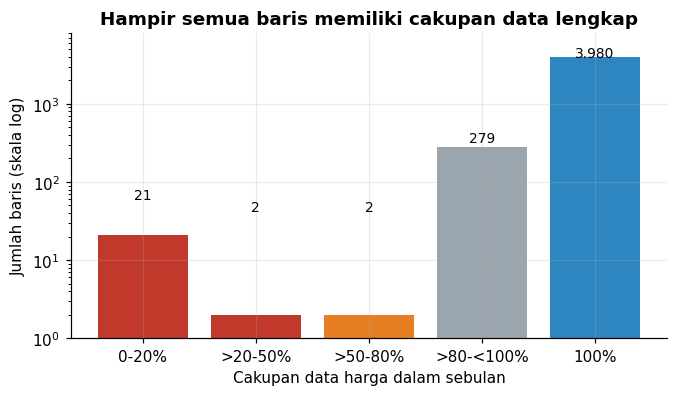

In [57]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(tab_cak.index, tab_cak.values, color=[MERAH, MERAH, ORANYE, ABU, BIRU])
for i, v in enumerate(tab_cak.values):
    ax.text(i, v + 40, f"{v:,}".replace(",", "."), ha="center", fontsize=9)
ax.set_yscale("log"); ax.set_ylim(1, 8000)
ax.set_xlabel("Cakupan data harga dalam sebulan"); ax.set_ylabel("Jumlah baris (skala log)")
ax.set_title("Hampir semua baris memiliki cakupan data lengkap")
simpan(fig, "00_distribusi_cakupan"); plt.show()

**Keputusan:** baris dengan cakupan di bawah 50% (kurang dari separuh bulan) diberi tanda `flag_data_parsial` dan **dikeluarkan dari analisis utama**, tetapi tidak dihapus dari file bersih. Alasannya: harga dari hanya beberapa hari sangat bergantung pada hari mana yang kebetulan tercatat. Batas 50% dipilih karena dari tabel di atas baris yang bermasalah jelas terpisah (cakupan sangat rendah), sedangkan sisa baris yang tidak lengkap hampir semuanya masih berada di atas 80%. Untuk memastikan keputusan ini tidak mengubah kesimpulan, ada **analisis sensitivitas** di bagian 3.8 (hasil dengan dan tanpa baris tersebut).

### 2.6 Outlier
Outlier ditandai dengan aturan IQR (1,5 × IQR) per komoditas, **tanpa dihapus**. Lalu tiap titik dinilai dengan tiga pertanyaan:
- (a) apakah cakupan datanya lengkap (≥ 80%)?
- (b) apakah polanya muncul di banyak provinsi pada bulan yang sama, atau konsisten di provinsi itu sepanjang waktu (pola berulang), bukan satu titik terpencil?
- (c) apakah wajar secara ekonomi (dilihat dari polanya)?

Jika cakupan lengkap dan polanya jelas, titik dianggap kejadian ekonomi nyata dan dipertahankan. Jika cakupan rendah dan terpencil, dianggap kurang andal.

In [58]:
def tanda_iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)

df["flag_outlier_iqr"] = df.groupby("komoditas")["harga_median"].transform(tanda_iqr).fillna(False)

out = df[df["flag_outlier_iqr"]].copy()
# (b1) banyak provinsi sekaligus pada komoditas-bulan yang sama
n_prov_bulan = out.groupby(["komoditas", "periode"])["provinsi"].transform("nunique")
# (b2) berulang di provinsi-komoditas yang sama (ciri wilayah)
n_berulang = out.groupby(["komoditas", "provinsi"])["periode"].transform("nunique")

def nilai(r):
    lengkap = r["cakupan_persen"] >= 80
    pola_jelas = (r["n_prov_bulan"] >= 3) or (r["n_berulang"] >= 5)
    if lengkap and r["n_prov_bulan"] >= 3: return "Lonjakan serentak antarprovinsi (dipertahankan)"
    if lengkap and r["n_berulang"] >= 5:   return "Konsisten tinggi di wilayah tsb (dipertahankan)"
    if lengkap:                            return "Terpencil, cakupan lengkap (dipertahankan, dicatat)"
    return "Cakupan rendah (kurang andal, ikut aturan cakupan)"

out["n_prov_bulan"], out["n_berulang"] = n_prov_bulan, n_berulang
out["penilaian"] = out.apply(nilai, axis=1)
df["penilaian_outlier"] = out["penilaian"].reindex(df.index)

print("Outlier IQR per komoditas:")
print(out.groupby("komoditas").size().to_string())
print()
ringkas_out = out.groupby(["komoditas", "penilaian"]).size().rename("jumlah").reset_index()
ringkas_out

Outlier IQR per komoditas:
komoditas
Bawang Merah            9
Beras Medium            1
Cabai Rawit Merah       5
Minyak Goreng Curah    24



,komoditas,penilaian,jumlah
0,Bawang Merah,Lonjakan serentak antarprovinsi (dipertahankan),3
1,Bawang Merah,"Terpencil, cakupan lengkap (dipertahankan, dic...",6
2,Beras Medium,"Terpencil, cakupan lengkap (dipertahankan, dic...",1
3,Cabai Rawit Merah,Lonjakan serentak antarprovinsi (dipertahankan),5
4,Minyak Goreng Curah,"Cakupan rendah (kurang andal, ikut aturan caku...",6
5,Minyak Goreng Curah,Konsisten tinggi di wilayah tsb (dipertahankan),12
6,Minyak Goreng Curah,Lonjakan serentak antarprovinsi (dipertahankan),2
7,Minyak Goreng Curah,"Terpencil, cakupan lengkap (dipertahankan, dic...",4


In [59]:
print("Outlier per komoditas & provinsi:")
print(out.groupby(["komoditas", "provinsi"]).size().sort_values(ascending=False).head(12).to_string())
print()
print("Lonjakan cabai rawit serentak (komoditas-bulan dengan >= 3 provinsi outlier):")
lonjakan = out[(out["komoditas"] == "Cabai Rawit Merah") & (out["n_prov_bulan"] >= 3)]
print(lonjakan.groupby("periode")["provinsi"].apply(lambda s: ", ".join(sorted(s))).to_string())

Outlier per komoditas & provinsi:
komoditas            provinsi                 
Minyak Goreng Curah  Maluku Utara                 18
Bawang Merah         Papua                         4
Minyak Goreng Curah  Papua Barat                   3
                     Papua                         2
Bawang Merah         Maluku Utara                  2
                     DKI Jakarta                   2
Cabai Rawit Merah    Gorontalo                     1
Beras Medium         Papua Barat                   1
Bawang Merah         Kepulauan Bangka Belitung     1
Cabai Rawit Merah    Kalimantan Utara              1
                     Sulawesi Utara                1
                     Sulawesi Tengah               1

Lonjakan cabai rawit serentak (komoditas-bulan dengan >= 3 provinsi outlier):
periode
2023-12    Gorontalo, Kalimantan Utara, Maluku Utara, Sul...


Tidak ada outlier yang dihapus. Titik berharga tinggi dengan cakupan lengkap dan pola yang jelas (lonjakan serentak di beberapa provinsi pada bulan yang sama, atau konsisten tinggi di wilayah tertentu) dipertahankan karena kemungkinan besar mencerminkan kondisi harga yang sebenarnya dan menjadi bahan analisis. Titik dengan cakupan rendah sudah tertangani oleh aturan cakupan di 2.5. Penjelasan penyebab lonjakan **tidak** bisa dibuktikan dari dataset ini, jadi di laporan hanya ditulis sebagai pola yang teramati.

### 2.7 Penandaan akhir dan validasi

In [60]:
df["flag_harga_kosong"] = df["harga_median"].isna()
df["flag_data_parsial"] = (df["cakupan_persen"] < 50) | df["flag_harga_kosong"]
df["tahun"] = df["periode"].str[:4].astype(int)

catat("6a. Tandai data parsial (cakupan < 50% atau harga kosong)", int(df["flag_data_parsial"].sum()),
      "dipertahankan di file bersih, dikeluarkan dari analisis utama")
catat("6b. Tandai outlier IQR (tidak dihapus)", int(df["flag_outlier_iqr"].sum()),
      "dinilai satu per satu; semua dipertahankan")

# ---------- validasi akhir ----------
assert len(df) == 34 * 6 * 21
assert df.duplicated(KUNCI).sum() == 0
assert df["provinsi"].nunique() == 34 and df["komoditas"].nunique() == 6 and df["periode"].nunique() == 21
assert df[[c for c in kolom_angka if c != "harga_median"]].isna().sum().sum() == 0
assert df["cakupan_persen"].between(0, 100).all()
assert (df["harga_median"].dropna() > 0).all()
# QRIS harus satu nilai per tahun (bukan dijumlah)
assert df.groupby("tahun")["qris_pengguna_juta"].nunique().max() == 1
print("Semua pemeriksaan validasi lolos.")
pd.DataFrame(LOG)

Semua pemeriksaan validasi lolos.


,langkah,baris_terdampak,keterangan
0,1a. Seragamkan nama provinsi,508,134 variasi tulisan -> 34 provinsi
1,1b. Seragamkan nama komoditas,841,30 variasi tulisan -> 6 komoditas
2,2. Format bulan ke YYYY-MM,953,5 pola penulisan -> 1 pola; gagal parse = 0
3,3. Teks -> angka,13,"13 kolom numerik; format Rp, %, titik/koma dib..."
4,4. Buang duplikat,50,konflik nilai = 0; sisa 4284 baris
5,5. Pulihkan kosong: cakupan_persen,10,dari aturan pasti (nilai nasional bulanan / ni...
6,5. Pulihkan kosong: usd_idr_median,12,dari aturan pasti (nilai nasional bulanan / ni...
7,5. Pulihkan kosong: tren_beras_median,12,dari aturan pasti (nilai nasional bulanan / ni...
8,5. Pulihkan kosong: tren_cabai_median,12,dari aturan pasti (nilai nasional bulanan / ni...
9,5. Pulihkan kosong: tren_minyak_goreng_median,12,dari aturan pasti (nilai nasional bulanan / ni...


### 2.8 Perbandingan sebelum dan sesudah pra-pemrosesan

In [61]:
sebelum = {
    "Jumlah baris": len(raw),
    "Variasi tulisan provinsi": raw["provinsi"].nunique(),
    "Variasi tulisan komoditas": raw["komoditas"].nunique(),
    "Pola format bulan": raw["bulan"].map(pola).nunique(),
    "Kolom numerik bertipe teks": int(sum(not pd.api.types.is_numeric_dtype(raw[c]) for c in kolom_angka)),
    "Baris duplikat (kunci)": n_dup,
    "Sel kosong (kolom numerik)": int(kosong[kolom_angka].sum()),
    "Harga kosong": int((raw["harga_median"].str.strip() == "").sum()),
}
sesudah = {
    "Jumlah baris": len(df),
    "Variasi tulisan provinsi": df["provinsi"].nunique(),
    "Variasi tulisan komoditas": df["komoditas"].nunique(),
    "Pola format bulan": df["periode"].map(pola).nunique(),
    "Kolom numerik bertipe teks": int(sum(not pd.api.types.is_numeric_dtype(df[c]) for c in kolom_angka)),
    "Baris duplikat (kunci)": int(df.duplicated(KUNCI).sum()),
    "Sel kosong (kolom numerik)": int(df[kolom_angka].isna().sum().sum()),
    "Harga kosong": int(df["harga_median"].isna().sum()),
}
banding = pd.DataFrame({"Sebelum": sebelum, "Sesudah": sesudah})
banding

,Sebelum,Sesudah
Jumlah baris,4334,4284
Variasi tulisan provinsi,134,34
Variasi tulisan komoditas,30,6
Pola format bulan,5,1
Kolom numerik bertipe teks,13,0
Baris duplikat (kunci),50,0
Sel kosong (kolom numerik),93,5
Harga kosong,5,5


In [62]:
# statistik harga per komoditas: sebelum (angka hasil parse langsung, tanpa dedup) vs sesudah
tmp = raw.copy()
tmp["komoditas"] = tmp["komoditas"].map(baku_kom)
tmp["harga"] = tmp["harga_median"].map(ke_angka)
st_sebelum = tmp.groupby("komoditas")["harga"].agg(["count", "mean", "median"]).round(0)
st_sesudah = df[~df["flag_data_parsial"]].groupby("komoditas")["harga_median"].agg(["count", "mean", "median"]).round(0)
pd.concat({"Sebelum (setelah parse saja)": st_sebelum, "Sesudah (analisis utama)": st_sesudah}, axis=1)

Sebelum (setelah parse saja)                   Sesudah (analisis utama)                  
                                           count     mean   median                    count     mean   median
komoditas                                                                                                    
Bawang Merah                                 719  36135.0  35350.0                      714  36179.0  35402.0
Beras Medium                                 726  13062.0  13025.0                      714  13060.0  13020.0
Cabai Rawit Merah                            723  56134.0  54170.0                      697  56437.0  54480.0
Daging Ayam Ras                              723  37294.0  36190.0                      714  37287.0  36180.0
Gula Konsumsi                                717  16378.0  16520.0                      714  16384.0  16530.0
Minyak Goreng Curah                          721  15523.0  15230.0                      708  15469.0  15220.0

In [63]:
# simpan file bersih + log (untuk lampiran)
df.drop(columns=["bulan"]).to_csv("print_2026_ekonomi_clean.csv", index=False)
pd.DataFrame(LOG).to_csv("log_cleaning.csv", index=False)

# data untuk analisis utama
valid = df[~df["flag_data_parsial"]].copy()
print("Baris file bersih:", len(df), "| baris analisis utama:", len(valid))

Baris file bersih: 4284 | baris analisis utama: 4261


## 3. Exploratory Data Analysis (EDA)

Alur EDA: (3.1) gambaran umum harga -> (3.2) pergerakan harga nasional -> (3.3) kestabilan harga -> (3.4) kaitan dengan kurs dan minat pencarian -> (3.5) ketimpangan harga antarprovinsi -> (3.6) akses internet -> (3.7) hubungan harga dan akses internet, serta provinsi prioritas -> (3.8) uji sensitivitas -> (3.9) konteks QRIS.

Karena satuan harga antarkomoditas belum terverifikasi, perbandingan memakai **indeks**, bukan level rupiah.

### 3.1 Gambaran umum harga per komoditas

In [64]:
desk = valid.groupby("komoditas")["harga_median"].agg(["count", "mean", "median", "std", "min", "max"])
desk["CV (%)"] = desk["std"] / desk["mean"] * 100
desk.round(1)

,count,mean,median,std,min,max,CV (%)
komoditas,,,,,,,
Bawang Merah,714,36178.9,35402.5,9717.1,15610.0,64980.0,26.9
Beras Medium,714,13060.3,13020.0,1290.5,10280.0,16660.0,9.9
Cabai Rawit Merah,697,56436.8,54480.0,18530.5,20090.0,140100.0,32.8
Daging Ayam Ras,714,37286.9,36180.0,5897.8,25535.0,51940.0,15.8
Gula Konsumsi,714,16384.2,16530.0,1743.3,13200.0,20840.0,10.6
Minyak Goreng Curah,708,15469.2,15220.0,1354.1,13290.0,21910.0,8.8


Tabel di atas hanya dibaca per baris (per komoditas), tidak untuk membandingkan level antarkomoditas, karena satuan fisiknya belum pasti. Yang bisa dibandingkan antarkomoditas adalah koefisien variasi (CV), karena CV tidak bergantung pada satuan.

### 3.2 Pergerakan harga nasional (indeks, Januari 2023 = 100)

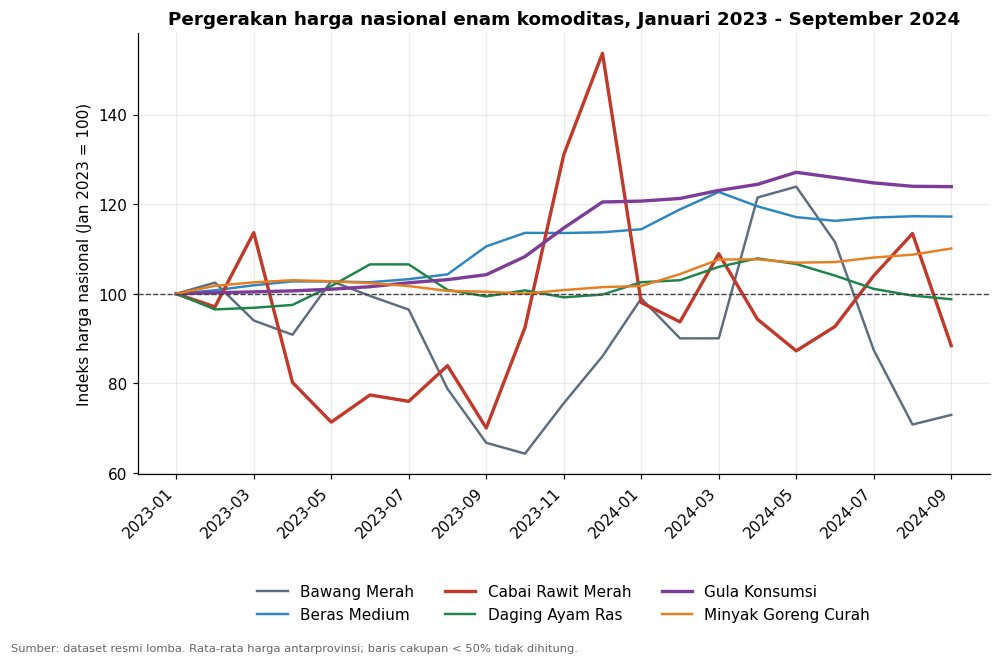

Indeks Sep 2024 terhadap Jan 2023:
komoditas
Gula Konsumsi          123.9
Beras Medium           117.2
Minyak Goreng Curah    110.1
Daging Ayam Ras         98.8
Cabai Rawit Merah       88.4
Bawang Merah            73.0



,bulan puncak,indeks puncak
komoditas,,
Bawang Merah,2024-05,123.9
Beras Medium,2024-03,122.7
Cabai Rawit Merah,2023-12,153.7
Daging Ayam Ras,2024-04,107.9
Gula Konsumsi,2024-05,127.1
Minyak Goreng Curah,2024-09,110.1


In [65]:
# rata-rata harga antarprovinsi tiap komoditas-bulan, lalu diindeks ke Januari 2023
nas = valid.groupby(["komoditas", "periode"])["harga_median"].mean().unstack(0)
nas_idx = nas / nas.iloc[0] * 100

fig, ax = plt.subplots(figsize=(10, 5.2))
for k in nas_idx.columns:
    ax.plot(nas_idx.index, nas_idx[k], label=k, color=WARNA_KOM[k], lw=2.2 if k in ["Cabai Rawit Merah", "Gula Konsumsi"] else 1.6)
ax.axhline(100, color="#444", ls="--", lw=0.9)
ax.set_xticks(nas_idx.index[::2]); plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_ylabel("Indeks harga nasional (Jan 2023 = 100)")
ax.set_title("Pergerakan harga nasional enam komoditas, Januari 2023 - September 2024")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22))
fig.text(0.01, -0.2, "Sumber: dataset resmi lomba. Rata-rata harga antarprovinsi; baris cakupan < 50% tidak dihitung.", fontsize=7.5, color="#666")
simpan(fig, "01_tren_nasional"); plt.show()

akhir = nas_idx.iloc[-1].sort_values(ascending=False).round(1)
puncak = nas_idx.idxmax().to_frame("bulan puncak").join(nas_idx.max().round(1).rename("indeks puncak"))
print("Indeks Sep 2024 terhadap Jan 2023:"); print(akhir.to_string()); print()
puncak

**Hasil.** Pada September 2024 (Januari 2023 = 100): gula 124, beras 117, minyak goreng 110, daging ayam 99, cabai rawit 88, bawang merah 73. Cabai puncak 154 (Desember 2023), bawang puncak 124 (Mei 2024).
**Interpretasi.** Ada dua gaya: gula dan beras naik pelan tetapi menetap, cabai dan bawang naik-turun tajam.
**Implikasi.** Komoditas yang bergejolak butuh sistem peringatan dini (Solusi 2), yang naik pelan butuh pemantauan dan tinjauan tata niaga (Solusi 3).

### 3.3 Kestabilan harga antar waktu

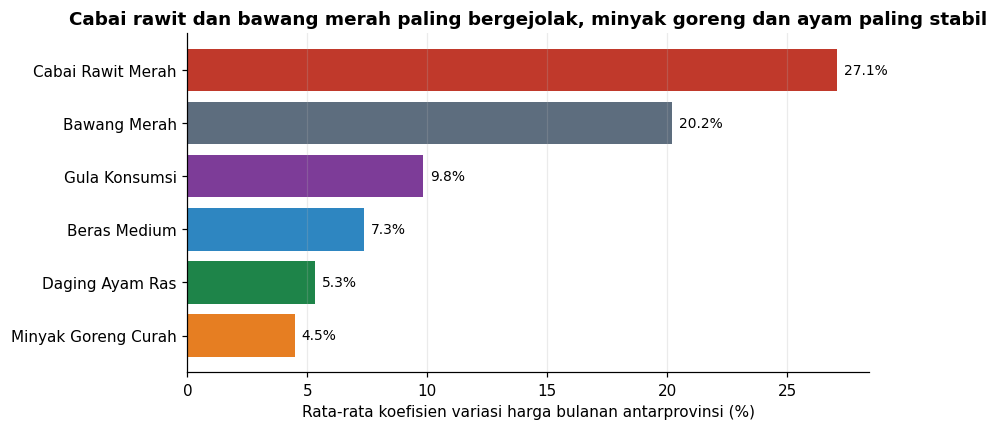

,0
komoditas,
Minyak Goreng Curah,4.5
Daging Ayam Ras,5.3
Beras Medium,7.3
Gula Konsumsi,9.8
Bawang Merah,20.2
Cabai Rawit Merah,27.1


In [66]:
# CV harga bulanan per provinsi-komoditas (min 12 bulan data), dirata-rata per komoditas
g = valid.groupby(["komoditas", "provinsi"])["harga_median"]
cv_pk = (g.std() / g.mean())[g.count() >= 12].unstack(0) * 100
cv_kom = cv_pk.mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(cv_kom.index, cv_kom.values, color=[WARNA_KOM[k] for k in cv_kom.index])
for i, v in enumerate(cv_kom.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("Rata-rata koefisien variasi harga bulanan antarprovinsi (%)")
ax.set_title("Cabai rawit dan bawang merah paling bergejolak, minyak goreng dan ayam paling stabil")
ax.grid(axis="y", alpha=0)
simpan(fig, "02_volatilitas_komoditas"); plt.show()
cv_kom.round(1)

**Hasil:** CV rata-rata: cabai rawit 27,1%, bawang merah 20,2%, gula 9,8%, beras 7,3%, daging ayam 5,3%, minyak goreng 4,5%.
**Interpretasi:** Cabai dan bawang 4-6 kali lebih bergejolak daripada minyak goreng.
**Implikasi:** Peringatan dini difokuskan ke cabai dan bawang merah.

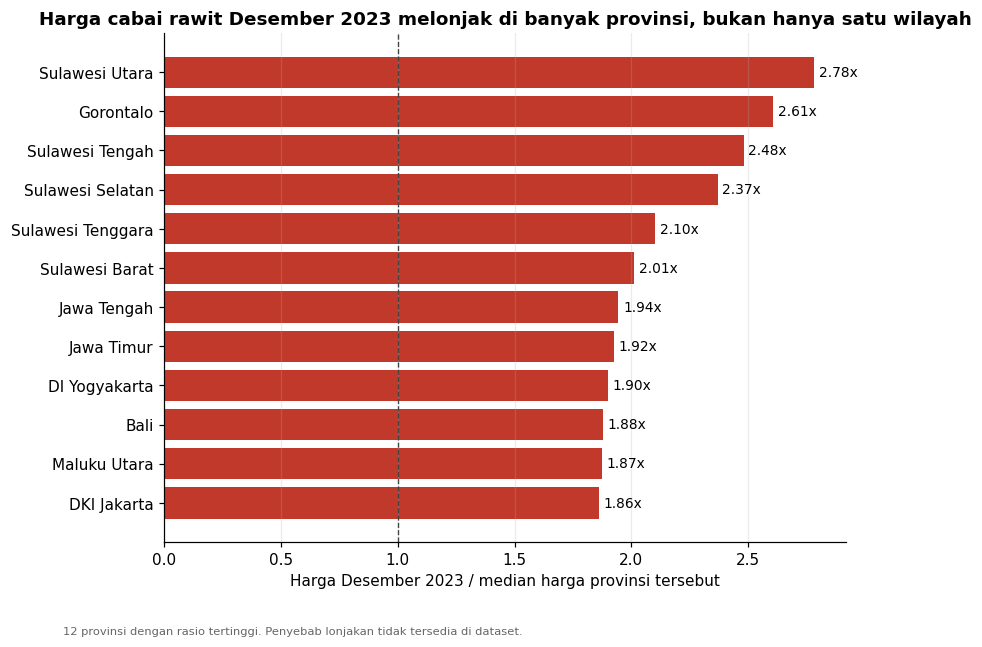

Provinsi dengan rasio >= 1,8x: Sulawesi Utara, Gorontalo, Sulawesi Tengah, Sulawesi Selatan, Sulawesi Tenggara, Sulawesi Barat, Jawa Tengah, Jawa Timur, DI Yogyakarta, Bali, Maluku Utara, DKI Jakarta, Jawa Barat, Banten, Kalimantan Utara
Rasio median 34 provinsi: 1.69


In [67]:
# lonjakan cabai rawit: rasio harga Desember 2023 terhadap median harga provinsi itu sepanjang periode
cb = valid[valid["komoditas"] == "Cabai Rawit Merah"].pivot(index="provinsi", columns="periode", values="harga_median")
rasio = (cb["2023-12"] / cb.median(axis=1)).dropna().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
top = rasio.head(12).iloc[::-1]
ax.barh(top.index, top.values, color=MERAH)
ax.axvline(1, color="#444", ls="--", lw=0.9)
for i, v in enumerate(top.values):
    ax.text(v + 0.02, i, f"{v:.2f}x", va="center", fontsize=9)
ax.set_xlabel("Harga Desember 2023 / median harga provinsi tersebut")
ax.set_title("Harga cabai rawit Desember 2023 melonjak di banyak provinsi, bukan hanya satu wilayah")
ax.grid(axis="y", alpha=0)
fig.text(0.01, -0.03, "12 provinsi dengan rasio tertinggi. Penyebab lonjakan tidak tersedia di dataset.", fontsize=7.5, color="#666")
simpan(fig, "03_lonjakan_cabai_des2023"); plt.show()
print("Provinsi dengan rasio >= 1,8x:", ", ".join(rasio[rasio >= 1.8].index))
print("Rasio median 34 provinsi:", round(rasio.median(), 2))

**Hasil:** 15 provinsi mencatat harga Desember 2023 sedikitnya 1,8 kali median provinsinya sendiri, termasuk sentra di Jawa dan Sulawesi (rasio median seluruh provinsi 1,69).
**Interpretasi:** Lonjakan serentak dan tersebar, jadi dibaca sebagai guncangan pasokan nasional, bukan efek jarak ke timur.
**Implikasi:** Responsnya harus serentak antarprovinsi (realokasi pasokan antarprovinsi dan operasi pasar), bukan pengiriman ke satu daerah.

### 3.4 Kurs USD/IDR dan minat pencarian vs harga nasional
Kurs dan Google Trends bersifat nasional bulanan, sehingga hanya bisa dibandingkan dengan **rata-rata harga nasional per bulan** (21 titik). Dengan 21 titik, korelasi gampang terdorong oleh tren yang sama-sama naik atau turun, jadi dilihat juga korelasi perubahan bulanan. Google Trends adalah indeks minat relatif, bukan jumlah pencarian.

In [68]:
bln = df.groupby("periode")[["usd_idr_median", "tren_beras_median", "tren_cabai_median", "tren_minyak_goreng_median"]].first()
bln.columns = ["Kurs USD/IDR", "Tren 'beras'", "Tren 'cabai'", "Tren 'minyak goreng'"]
gab = bln.join(nas)

def korelasi(x, y):
    r, p = stats.pearsonr(x, y); return r, p

pasangan = [("Kurs USD/IDR", k) for k in nas.columns] + \
           [("Tren 'beras'", "Beras Medium"), ("Tren 'cabai'", "Cabai Rawit Merah"), ("Tren 'minyak goreng'", "Minyak Goreng Curah")]
baris = []
for a, b in pasangan:
    r_lv, p_lv = korelasi(gab[a], gab[b])
    r_df, p_df = korelasi(gab[a].diff().dropna(), gab[b].diff().dropna())
    baris.append({"Variabel": a, "Harga": b, "r (level)": r_lv, "p (level)": p_lv, "r (perubahan bulanan)": r_df, "p (perubahan)": p_df})
kor = pd.DataFrame(baris).round(3)
kor

,Variabel,Harga,r (level),p (level),r (perubahan bulanan),p (perubahan)
0,Kurs USD/IDR,Bawang Merah,0.176,0.446,0.143,0.549
1,Kurs USD/IDR,Beras Medium,0.801,0.000,0.070,0.769
2,Kurs USD/IDR,Cabai Rawit Merah,0.296,0.192,0.120,0.615
3,Kurs USD/IDR,Daging Ayam Ras,0.321,0.156,0.080,0.736
4,Kurs USD/IDR,Gula Konsumsi,0.836,0.000,0.079,0.741
5,Kurs USD/IDR,Minyak Goreng Curah,0.583,0.006,-0.247,0.293
6,Tren 'beras',Beras Medium,-0.107,0.644,0.614,0.004
7,Tren 'cabai',Cabai Rawit Merah,0.387,0.083,0.429,0.059
8,Tren 'minyak goreng',Minyak Goreng Curah,-0.526,0.014,0.192,0.416


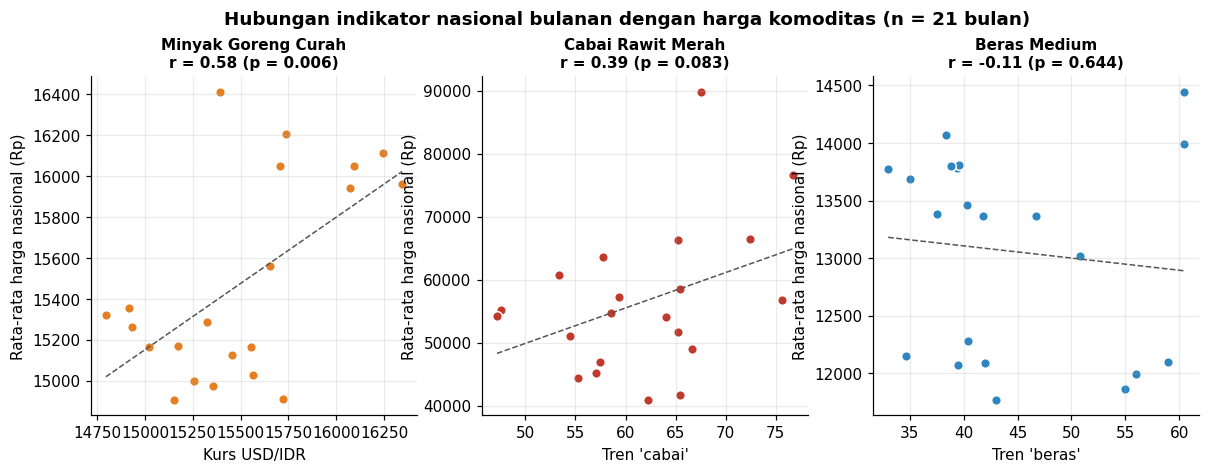

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (a, b, w) in zip(axes, [("Kurs USD/IDR", "Minyak Goreng Curah", ORANYE),
                                ("Tren 'cabai'", "Cabai Rawit Merah", MERAH),
                                ("Tren 'beras'", "Beras Medium", BIRU)]):
    ax.scatter(gab[a], gab[b], color=w, s=40, edgecolor="white")
    m, c = np.polyfit(gab[a], gab[b], 1)
    xs = np.linspace(gab[a].min(), gab[a].max(), 10)
    ax.plot(xs, m * xs + c, color="#555", ls="--", lw=1)
    r, p = stats.pearsonr(gab[a], gab[b])
    ax.set_title(f"{b}\nr = {r:.2f} (p = {p:.3f})", fontsize=10)
    ax.set_xlabel(a); ax.set_ylabel("Rata-rata harga nasional (Rp)")
fig.suptitle("Hubungan indikator nasional bulanan dengan harga komoditas (n = 21 bulan)", fontweight="bold", y=1.03)
simpan(fig, "04_kurs_tren_vs_harga"); plt.show()

**Hasil.** Pada level, kurs berkorelasi tinggi dengan beras dan gula, tetapi pada perubahan bulanan korelasinya kecil dan tidak signifikan. Perubahan Google Trends "beras" berkorelasi 0,61 (p = 0,004) dengan perubahan harga beras.
**Interpretasi.** Korelasi level hanya karena dua deret sama-sama naik. Kurs hanya naik 1,6%, gula naik 24%.
**Implikasi.** Kurs bukan penjelasan utama kenaikan gula dan beras. Pasokan dan tata niaga yang perlu ditinjau (Solusi 3).

Catatan interpretasi metodologis: ini korelasi pada 21 bulan, bukan bukti sebab-akibat. Hasil level dan hasil perubahan bulanan perlu dibaca berdampingan; jika level tampak kuat tetapi perubahan bulanan lemah, hubungannya kemungkinan hanya karena dua deret sama-sama punya tren.

### 3.5 Ketimpangan harga antarprovinsi
Indeks harga dibuat per komoditas-bulan: harga provinsi dibagi rata-rata nasional pada bulan yang sama dikali 100. Dengan begitu perbedaan musim dan perbedaan satuan antarkomoditas tidak mengganggu. Indeks provinsi adalah rata-rata dari bulan-bulan yang tersedia, lalu dirata-ratakan lintas komoditas. Pasangan provinsi-komoditas dengan data valid kurang dari 12 bulan tidak dipakai (hanya berlaku untuk Aceh – Cabai Rawit Merah).

In [70]:
valid["indeks_rel"] = valid["harga_median"] / valid.groupby(["komoditas", "periode"])["harga_median"].transform("mean") * 100
n_bln = valid.groupby(["komoditas", "provinsi"])["periode"].nunique()
ok = n_bln[n_bln >= 12].index
v12 = valid.set_index(["komoditas", "provinsi"]).loc[ok].reset_index()
print("Pasangan provinsi-komoditas yang dikeluarkan (< 12 bulan valid):", [tuple(i) for i in n_bln[n_bln < 12].index])

indeks_pk = v12.groupby(["provinsi", "komoditas"])["indeks_rel"].mean().unstack()   # provinsi x komoditas
indeks_prov = indeks_pk.mean(axis=1).rename("indeks_harga")
print(indeks_prov.sort_values(ascending=False).round(1).head(10).to_string())

Pasangan provinsi-komoditas yang dikeluarkan (< 12 bulan valid): [('Cabai Rawit Merah', 'Aceh')]
provinsi
Papua                        126.0
Papua Barat                  125.2
Maluku Utara                 124.4
Kalimantan Utara             118.2
Maluku                       117.9
Kalimantan Barat             108.3
Kalimantan Tengah            106.4
Kalimantan Timur             105.4
Kepulauan Riau               104.9
Kepulauan Bangka Belitung    103.5


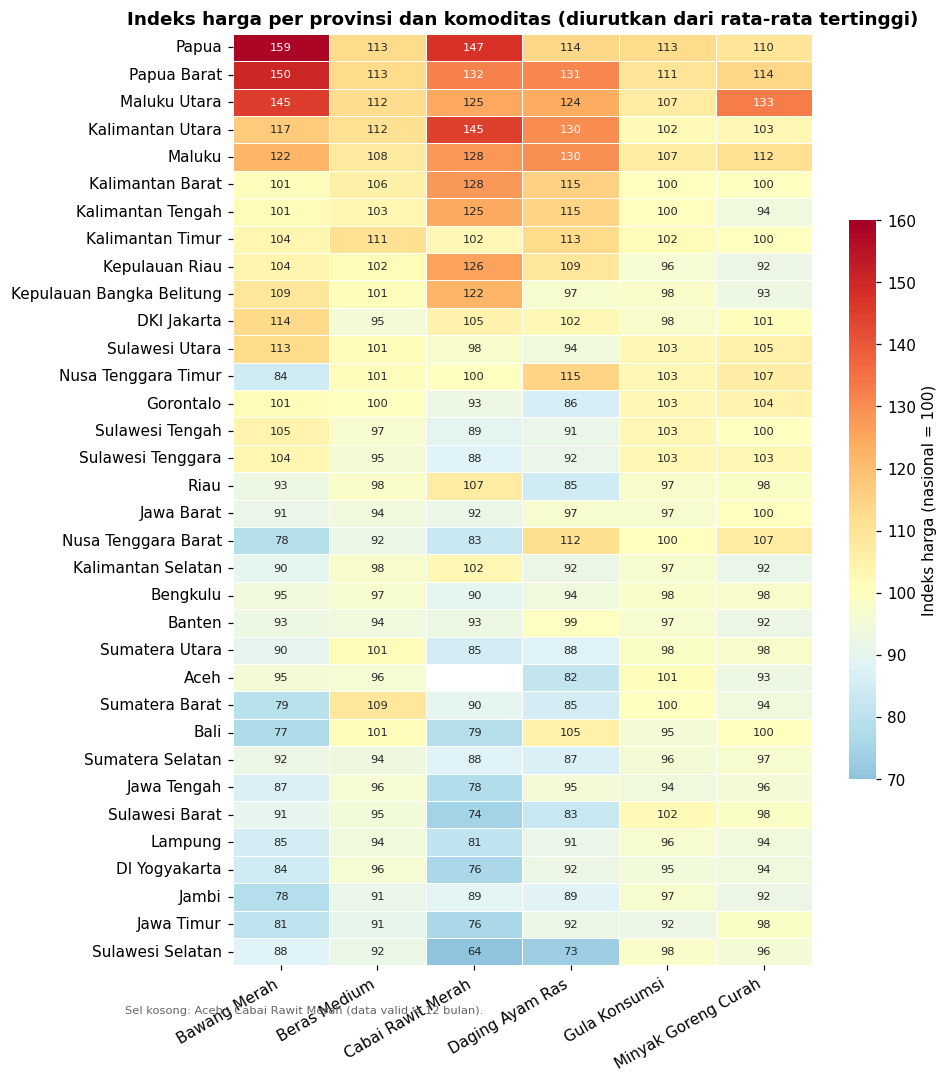

In [71]:
urut = indeks_pk.mean(axis=1).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8.5, 11))
sns.heatmap(indeks_pk.loc[urut], annot=True, fmt=".0f", cmap="RdYlBu_r", center=100, vmin=70, vmax=160,
            linewidths=0.4, linecolor="white", cbar_kws={"label": "Indeks harga (nasional = 100)", "shrink": 0.6},
            annot_kws={"size": 7.5}, ax=ax)
ax.set_title("Indeks harga per provinsi dan komoditas (diurutkan dari rata-rata tertinggi)")
ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.text(0.01, 0.07, "Sel kosong: Aceh - Cabai Rawit Merah (data valid < 12 bulan).", fontsize=7.5, color="#666")
simpan(fig, "05_heatmap_provinsi_komoditas"); plt.show()

**Hasil.** Papua (126,0), Papua Barat (125,2), Maluku Utara (124,4), Kalimantan Utara (118,2), dan Maluku (117,9) berindeks tertinggi. Merah paling pekat pada bawang merah dan cabai.
**Interpretasi.** Selisih terbesar ada pada komoditas segar yang cepat rusak dan mahal diangkut (pola konsisten dengan hambatan logistik, tetapi ongkos angkut tidak ada di dataset, jadi ini dugaan).
**Implikasi.** Intervensi di timur paling berdampak bila dipusatkan pada bawang merah, cabai, dan daging ayam (Solusi 1).

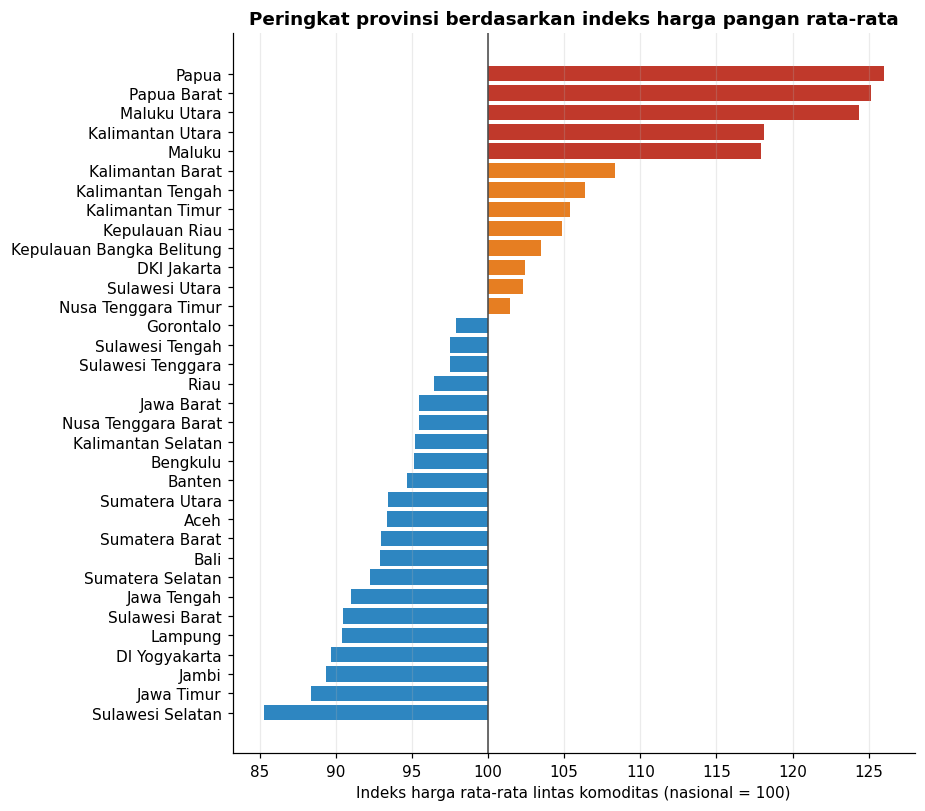

In [72]:
top_m = indeks_prov.sort_values()
fig, ax = plt.subplots(figsize=(8, 8.5))
ax.barh(top_m.index, top_m.values - 100, left=100, color=[MERAH if v > 110 else (ORANYE if v > 100 else BIRU) for v in top_m.values])
ax.axvline(100, color="#444", lw=1)
ax.set_xlabel("Indeks harga rata-rata lintas komoditas (nasional = 100)")
ax.set_title("Peringkat provinsi berdasarkan indeks harga pangan rata-rata")
ax.grid(axis="y", alpha=0)
simpan(fig, "06_peringkat_indeks_harga"); plt.show()

**Hasil.** Peringkat indeks harga 34 provinsi, dengan 5 provinsi di atas 117.
**Interpretasi.** Empat provinsi berindeks di atas 110 pada 21 dari 21 bulan, Maluku pada 20 dari 21 bulan (lihat sel 3.11), jadi premium harganya menetap, bukan sesaat.
**Implikasi.** Butuh solusi struktural (koridor pasokan), bukan operasi pasar sesaat.

### 3.6 Akses internet antarprovinsi (2023)

In [73]:
prov = df.groupby("provinsi")[["internet_laki_laki_2023", "internet_perempuan_2023"]].first()
prov.columns = ["int_laki", "int_perempuan"]
prov["internet"] = prov[["int_laki", "int_perempuan"]].mean(axis=1)
prov["gap_gender"] = prov["int_laki"] - prov["int_perempuan"]
prov["indeks_harga"] = indeks_prov
print(prov[["int_laki", "int_perempuan", "internet", "gap_gender"]].describe().round(1).to_string())
print()
print("Provinsi dengan akses internet terendah:")
print(prov["internet"].sort_values().head(5).round(1).to_string())
print()
print("Provinsi dengan gap gender terbesar:")
print(prov["gap_gender"].sort_values(ascending=False).head(5).round(1).to_string())
n_lk = int((prov["gap_gender"] > 0).sum())
print(f"\nProvinsi dengan akses laki-laki > perempuan: {n_lk} dari {len(prov)}")

       int_laki  int_perempuan  internet  gap_gender
count      34.0           34.0      34.0        34.0
mean       69.3           65.0      67.2         4.4
std        10.5           10.5      10.4         2.7
min        31.3           28.4      29.8        -1.9
25%        63.6           60.3      63.4         3.1
50%        70.7           65.4      67.5         4.5
75%        75.0           69.1      72.1         5.8
max        88.0           86.0      86.7        10.0

Provinsi dengan akses internet terendah:
provinsi
Papua                  29.8
Nusa Tenggara Timur    51.1
Maluku Utara           53.5
Sulawesi Tengah        58.2
Maluku                 58.5

Provinsi dengan gap gender terbesar:
provinsi
Bali           10.0
Aceh            8.3
Jawa Timur      8.1
Jambi           7.5
Jawa Tengah     7.2

Provinsi dengan akses laki-laki > perempuan: 32 dari 34


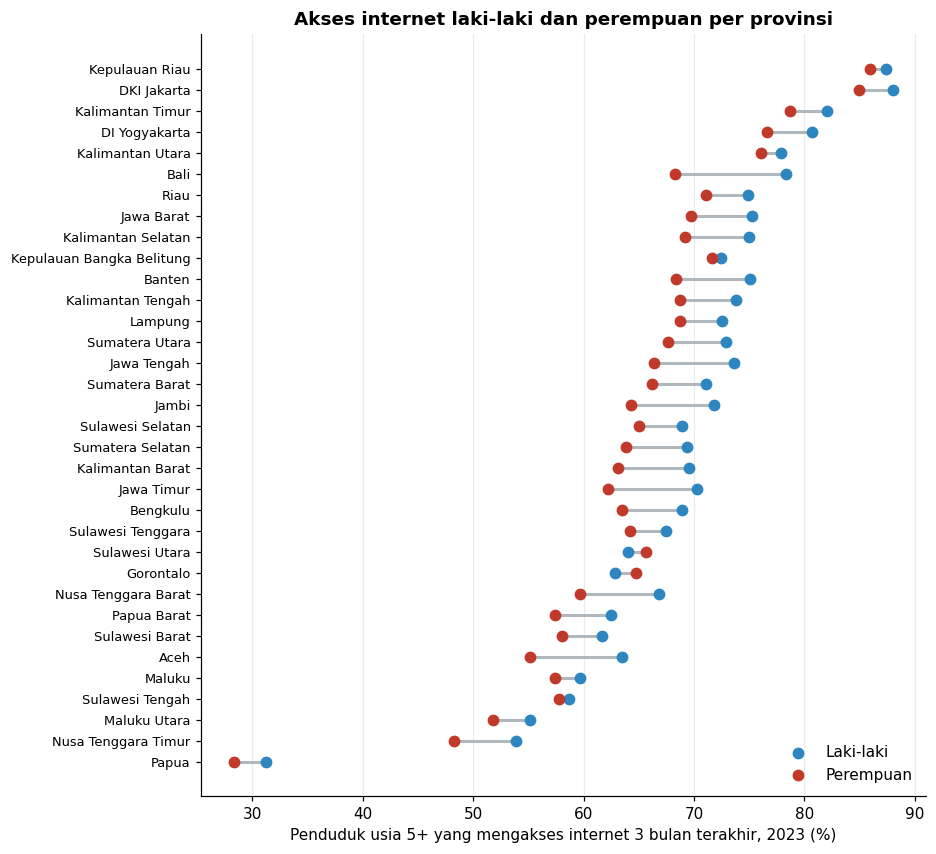

In [74]:
u = prov.sort_values("internet")
fig, ax = plt.subplots(figsize=(8.5, 9))
y = np.arange(len(u))
ax.hlines(y, u["int_perempuan"], u["int_laki"], color="#B0B7BD", lw=2, zorder=1)
ax.scatter(u["int_laki"], y, s=45, c=BIRU, label="Laki-laki", zorder=2)
ax.scatter(u["int_perempuan"], y, s=45, c=MERAH, label="Perempuan", zorder=2)
ax.set_yticks(y); ax.set_yticklabels(u.index, fontsize=8.5)
ax.set_xlabel("Penduduk usia 5+ yang mengakses internet 3 bulan terakhir, 2023 (%)")
ax.set_title("Akses internet laki-laki dan perempuan per provinsi")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", alpha=0)
simpan(fig, "07_akses_internet_gender"); plt.show()

**Hasil.** Akses laki-laki lebih tinggi di 32 dari 34 provinsi, selisih rata-rata 4,4 poin. Selisih terbesar: Bali 10,0, Aceh 8,3, Jawa Timur 8,1. Papua hanya 29,8% (rata-rata laki-laki dan perempuan).
**Interpretasi.** Besar celah gender nyaris tidak berkaitan dengan tingkat akses (korelasi 0,02).
**Implikasi.** Program perluasan akses dan program kesetaraan gender perlu dirancang terpisah (Solusi 4).

### 3.7 Harga pangan dan akses internet
Pertanyaan: apakah provinsi dengan harga pangan relatif mahal cenderung punya akses internet lebih rendah, dan provinsi mana yang menanggung dua keterbatasan sekaligus? Dengan 34 provinsi (n kecil) dipakai korelasi Spearman supaya tidak terlalu dipengaruhi satu-dua provinsi ekstrem.

In [75]:
rho, p_rho = stats.spearmanr(prov["internet"], prov["indeks_harga"])
r_p, p_p = stats.pearsonr(prov["internet"], prov["indeks_harga"])
print(f"Internet vs indeks harga (34 provinsi): Spearman rho = {rho:.2f} (p = {p_rho:.3f}) | Pearson r = {r_p:.2f} (p = {p_p:.3f})")

per_kom = []
for k in indeks_pk.columns:
    s = indeks_pk[k].dropna()
    r, p = stats.spearmanr(prov.loc[s.index, "internet"], s)
    per_kom.append({"komoditas": k, "n provinsi": len(s), "Spearman rho": r, "p": p})
pd.DataFrame(per_kom).round(3)

Internet vs indeks harga (34 provinsi): Spearman rho = -0.15 (p = 0.411) | Pearson r = -0.37 (p = 0.030)


,komoditas,n provinsi,Spearman rho,p
0,Bawang Merah,34,-0.184,0.296
1,Beras Medium,34,-0.086,0.629
2,Cabai Rawit Merah,33,-0.011,0.951
3,Daging Ayam Ras,34,0.012,0.947
4,Gula Konsumsi,34,-0.646,0.000
5,Minyak Goreng Curah,34,-0.490,0.003


In [76]:
# Pearson (r = -0,37) lebih kuat daripada Spearman, kemungkinan karena Papua (internet 29,8%) sangat ekstrem -> cek tanpa Papua
tanpa = prov.drop(index="Papua")
r1, p1 = stats.pearsonr(tanpa["internet"], tanpa["indeks_harga"])
r2, p2 = stats.spearmanr(tanpa["internet"], tanpa["indeks_harga"])
print(f"Tanpa Papua (n = 33): Pearson r = {r1:.2f} (p = {p1:.3f}) | Spearman rho = {r2:.2f} (p = {p2:.3f})")

Tanpa Papua (n = 33): Pearson r = -0.15 (p = 0.396) | Spearman rho = -0.07 (p = 0.717)


In [77]:
# kuadran: batas harga = rata-rata nasional (100), batas internet = median 34 provinsi
med_int = prov["internet"].median()
prov["kuadran"] = np.select(
    [(prov.indeks_harga > 100) & (prov.internet < med_int),
     (prov.indeks_harga > 100),
     (prov.internet < med_int)],
    ["Mahal & internet rendah", "Mahal & internet tinggi", "Murah & internet rendah"],
    default="Murah & internet tinggi")

# skor ketimpangan ganda: rata-rata z-score(indeks harga) dan z-score(kebalikan internet)
z = lambda s: (s - s.mean()) / s.std()
prov["skor"] = (z(prov["indeks_harga"]) + z(-prov["internet"])) / 2
prioritas = prov.sort_values("skor", ascending=False).head(5).index.tolist()
print("Median internet:", round(med_int, 1))
print(prov["kuadran"].value_counts().to_string())
print()
print("Lima provinsi skor tertinggi:", prioritas)
prov.loc[prioritas, ["indeks_harga", "internet", "gap_gender", "skor"]].round(2)

Median internet: 67.5
kuadran
Murah & internet tinggi    11
Murah & internet rendah    10
Mahal & internet rendah     7
Mahal & internet tinggi     6

Lima provinsi skor tertinggi: ['Papua', 'Maluku Utara', 'Papua Barat', 'Maluku', 'Nusa Tenggara Timur']


,indeks_harga,internet,gap_gender,skor
provinsi,,,,
Papua,125.98,29.80,2.91,2.98
Maluku Utara,124.37,53.46,3.42,1.77
Papua Barat,125.18,59.92,5.09,1.49
Maluku,117.91,58.54,2.25,1.23
Nusa Tenggara Timur,101.43,51.10,5.63,0.83


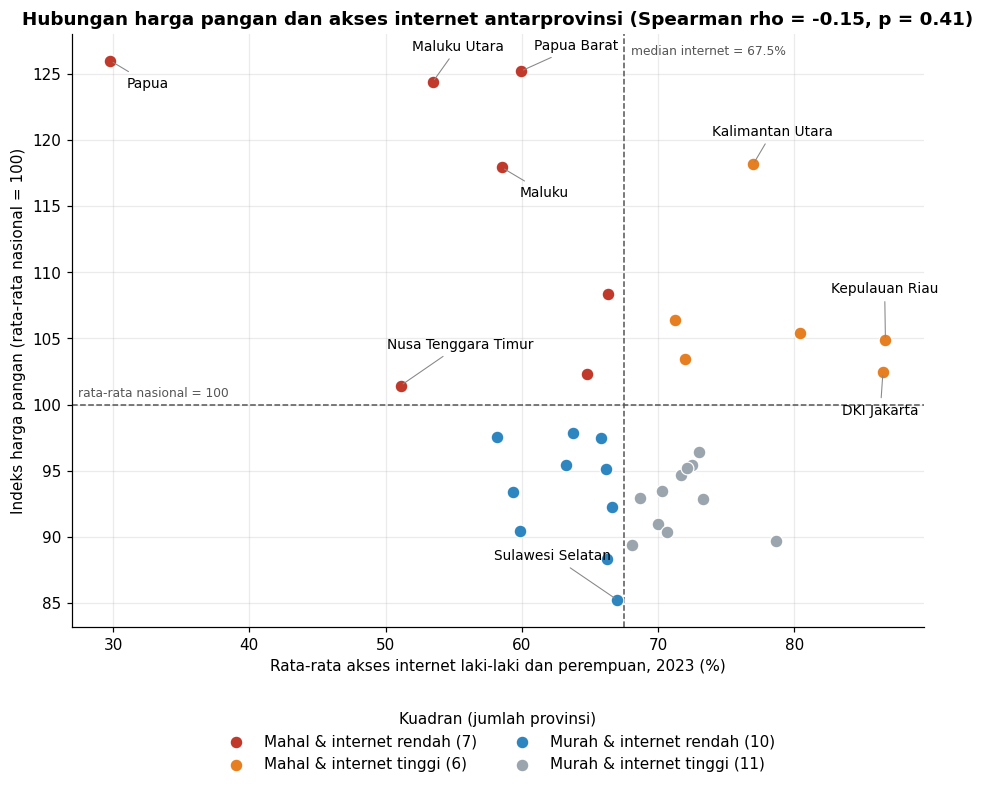

In [78]:
WARNA_Q = {"Mahal & internet rendah": MERAH, "Mahal & internet tinggi": ORANYE,
           "Murah & internet rendah": BIRU, "Murah & internet tinggi": ABU}
fig, ax = plt.subplots(figsize=(10, 7))
for nama, g in prov.groupby("kuadran"):
    ax.scatter(g["internet"], g["indeks_harga"], s=70, c=WARNA_Q[nama], label=f"{nama} ({len(g)})",
               edgecolor="white", linewidth=0.8, zorder=3)
ax.axhline(100, color="#555", ls="--", lw=1); ax.axvline(med_int, color="#555", ls="--", lw=1)
ax.text(ax.get_xlim()[0] + 0.5, 100.6, "rata-rata nasional = 100", fontsize=8, color="#555")
ax.text(med_int + 0.5, ax.get_ylim()[1] - 0.8, f"median internet = {med_int:.1f}%", fontsize=8, color="#555", va="top")
label = {"Papua": (1.2, -2.0), "Papua Barat": (1.0, 1.6), "Maluku Utara": (-1.5, 2.4), "Maluku": (1.3, -2.2),
         "Nusa Tenggara Timur": (-1.0, 2.8), "Kalimantan Utara": (-3.0, 2.2), "DKI Jakarta": (-3.0, -3.2),
         "Kepulauan Riau": (-4.0, 3.6), "Sulawesi Selatan": (-9.0, 3.0)}
for p_, (dx, dy) in label.items():
    ax.annotate(p_, (prov.loc[p_, "internet"], prov.loc[p_, "indeks_harga"]),
                xytext=(prov.loc[p_, "internet"] + dx, prov.loc[p_, "indeks_harga"] + dy),
                fontsize=9, arrowprops=dict(arrowstyle="-", color="#888", lw=0.7))
ax.set_xlabel("Rata-rata akses internet laki-laki dan perempuan, 2023 (%)")
ax.set_ylabel("Indeks harga pangan (rata-rata nasional = 100)")
ax.set_title(f"Hubungan harga pangan dan akses internet antarprovinsi (Spearman rho = {rho:.2f}, p = {p_rho:.2f})")
ax.legend(title="Kuadran (jumlah provinsi)", frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
simpan(fig, "08_kuadran_harga_internet"); plt.show()

**Hasil.** 11 provinsi murah dan internet tinggi, 10 murah dan internet rendah, 7 mahal dan internet rendah, 6 mahal dan internet tinggi. Spearman rho = -0,15 (p = 0,41).
**Interpretasi.** Akses internet rendah tidak otomatis berarti harga mahal. Kalimantan Utara berinternet 77% tetapi indeks 118.
**Implikasi.** Memperluas internet saja tidak akan otomatis menurunkan harga. Digitalisasi harus dipadukan dengan perbaikan distribusi.

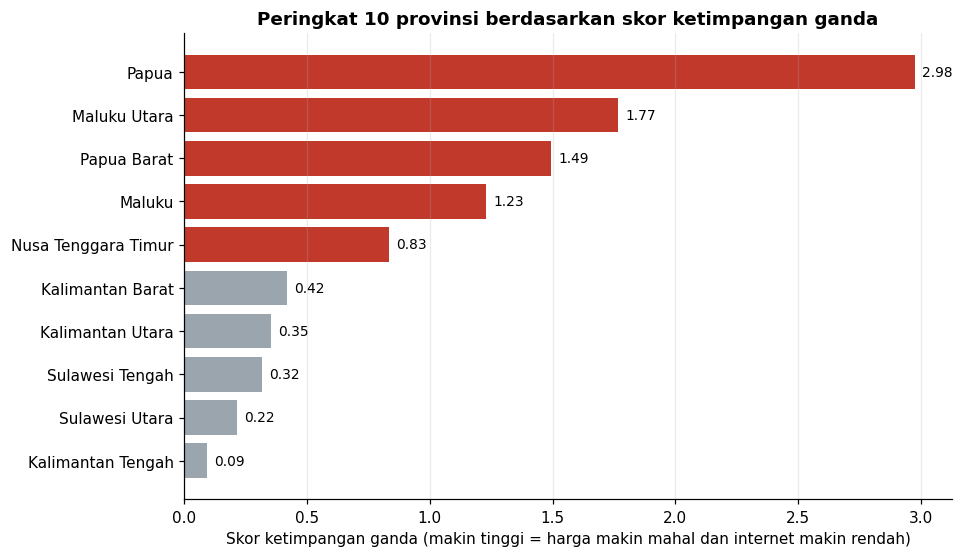

In [79]:
top = prov.sort_values("skor", ascending=False).head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index, top["skor"], color=[MERAH if p_ in prioritas else ABU for p_ in top.index])
for i, v in enumerate(top["skor"]):
    ax.text(v + 0.03, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlabel("Skor ketimpangan ganda (makin tinggi = harga makin mahal dan internet makin rendah)")
ax.set_title("Peringkat 10 provinsi berdasarkan skor ketimpangan ganda")
ax.grid(axis="y", alpha=0)
simpan(fig, "09_peringkat_skor"); plt.show()

**Hasil.** Skor ketimpangan ganda tertinggi: Papua 2,98, Maluku Utara 1,77, Papua Barat 1,49, Maluku 1,23, Nusa Tenggara Timur 0,83.
**Interpretasi.** Empat teratas stabil pada semua uji sensitivitas (sel 3.8). Hanya peringkat kelima berubah bila bobot harga 70%.
**Implikasi.** Kelima provinsi ini yang pertama perlu mendapat program.

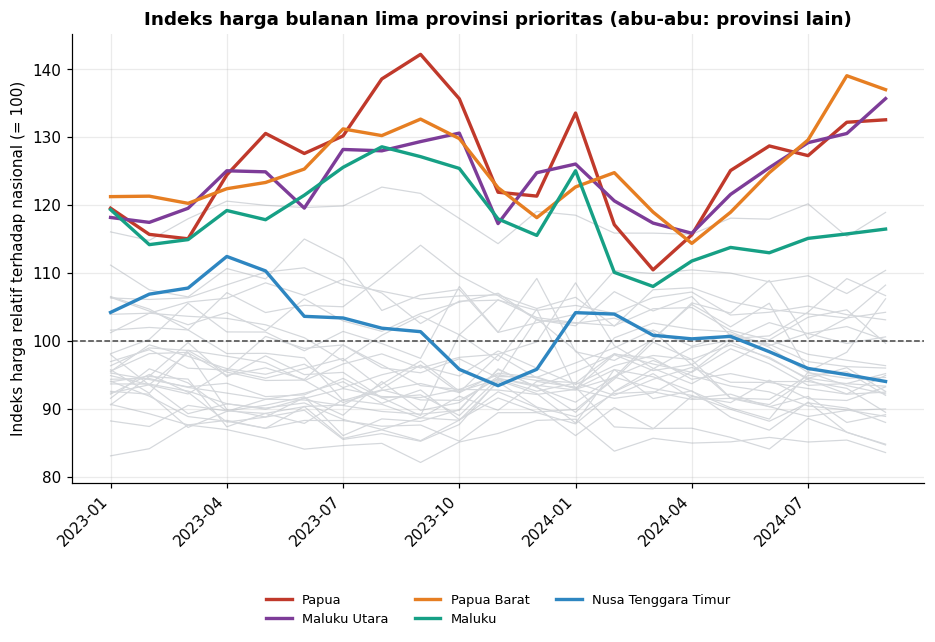

In [80]:
# gambaran provinsi prioritas: indeks harga relatif per bulan
rel = valid.groupby(["provinsi", "periode"])["indeks_rel"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(10, 5.3))
for p_ in rel.columns:
    ax.plot(rel.index, rel[p_], color="#D5D8DC", lw=0.8, zorder=1)
palet = [MERAH, UNGU, ORANYE, "#16A085", BIRU]
for p_, w in zip(prioritas, palet):
    ax.plot(rel.index, rel[p_], color=w, lw=2.2, label=p_, zorder=3)
ax.axhline(100, color="#444", ls="--", lw=1)
ax.set_xticks(rel.index[::3]); plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_ylabel("Indeks harga relatif terhadap nasional (= 100)")
ax.set_title("Indeks harga bulanan lima provinsi prioritas (abu-abu: provinsi lain)")
ax.legend(frameon=False, ncol=3, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.22))
simpan(fig, "10_tren_provinsi_prioritas"); plt.show()

**Hasil.** Empat provinsi timur bergerak jauh di atas 100. Nusa Tenggara Timur hanya 2 dari 21 bulan di atas 110 dan turun di bawah 100 pada akhir periode.
**Interpretasi.** Nusa Tenggara Timur menjadi prioritas karena akses internetnya, bukan harganya.
**Implikasi.** Bantuan untuk Nusa Tenggara Timur diarahkan ke inklusi digital, empat provinsi timur lainnya ke logistik.

In [81]:
# profil provinsi prioritas: komoditas termahal & kesenjangan gender
baris = []
for p_ in prioritas:
    kom = indeks_pk.loc[p_].dropna().sort_values(ascending=False)
    baris.append({"Provinsi": p_, "Indeks harga": round(prov.loc[p_, "indeks_harga"], 1),
                  "Akses internet (%)": round(prov.loc[p_, "internet"], 1),
                  "Gap gender (poin)": round(prov.loc[p_, "gap_gender"], 1),
                  "Skor": round(prov.loc[p_, "skor"], 2),
                  "Komoditas termahal (indeks)": f"{kom.index[0]} ({kom.iloc[0]:.0f})",
                  "Komoditas termahal ke-2": f"{kom.index[1]} ({kom.iloc[1]:.0f})"})
profil = pd.DataFrame(baris)
profil

,Provinsi,Indeks harga,Akses internet (%),Gap gender (poin),Skor,Komoditas termahal (indeks),Komoditas termahal ke-2
0,Papua,126.0,29.8,2.9,2.98,Bawang Merah (159),Cabai Rawit Merah (147)
1,Maluku Utara,124.4,53.5,3.4,1.77,Bawang Merah (145),Minyak Goreng Curah (133)
2,Papua Barat,125.2,59.9,5.1,1.49,Bawang Merah (150),Cabai Rawit Merah (132)
3,Maluku,117.9,58.5,2.2,1.23,Daging Ayam Ras (130),Cabai Rawit Merah (128)
4,Nusa Tenggara Timur,101.4,51.1,5.6,0.83,Daging Ayam Ras (115),Minyak Goreng Curah (107)


### 3.8 Uji sensitivitas
Apakah daftar provinsi prioritas berubah jika keputusan cleaning dan pembobotan diubah? Empat variasi dibandingkan dengan hasil utama:
- **B**: semua baris dipakai (tanpa aturan cakupan < 50%)
- **C**: indeks harga memakai median antarkomoditas (bukan rata-rata)
- **D**: akses internet memakai angka perempuan saja
- **E**: bobot skor 70% harga, 30% internet

In [82]:
def hitung(data, agg="mean", sumber_internet="rata", bobot_harga=0.5, min_bln=12):
    d = data.copy()
    d["rel"] = d["harga_median"] / d.groupby(["komoditas", "periode"])["harga_median"].transform("mean") * 100
    nb = d.groupby(["komoditas", "provinsi"])["periode"].nunique()
    d = d.set_index(["komoditas", "provinsi"]).loc[nb[nb >= min_bln].index].reset_index()
    ipk = d.groupby(["provinsi", "komoditas"])["rel"].mean().unstack()
    ih = ipk.mean(axis=1) if agg == "mean" else ipk.median(axis=1)
    pv = prov[["int_laki", "int_perempuan", "internet"]].copy()
    inet = pv["internet"] if sumber_internet == "rata" else pv["int_perempuan"]
    sk = bobot_harga * z(ih) + (1 - bobot_harga) * z(-inet)
    return sk.sort_values(ascending=False)

semua = df[df["harga_median"].notna()]
varian = {
    "A. Utama": hitung(valid),
    "B. Semua baris dipakai": hitung(semua),
    "C. Median antarkomoditas": hitung(valid, agg="median"),
    "D. Internet perempuan saja": hitung(valid, sumber_internet="perempuan"),
    "E. Bobot 70% harga": hitung(valid, bobot_harga=0.7),
}
tabel_sens = pd.DataFrame({k: v.head(5).index.tolist() for k, v in varian.items()}, index=[f"#{i}" for i in range(1, 6)])
print(tabel_sens.T.to_string())
utama5 = set(varian["A. Utama"].head(5).index)
print()
for k, v in varian.items():
    print(f"{k}: {len(utama5 & set(v.head(5).index))} dari 5 provinsi sama dengan hasil utama")

                               #1            #2           #3      #4                   #5
A. Utama                    Papua  Maluku Utara  Papua Barat  Maluku  Nusa Tenggara Timur
B. Semua baris dipakai      Papua  Maluku Utara  Papua Barat  Maluku  Nusa Tenggara Timur
C. Median antarkomoditas    Papua  Maluku Utara  Papua Barat  Maluku  Nusa Tenggara Timur
D. Internet perempuan saja  Papua  Maluku Utara  Papua Barat  Maluku  Nusa Tenggara Timur
E. Bobot 70% harga          Papua  Maluku Utara  Papua Barat  Maluku     Kalimantan Utara

A. Utama: 5 dari 5 provinsi sama dengan hasil utama
B. Semua baris dipakai: 5 dari 5 provinsi sama dengan hasil utama
C. Median antarkomoditas: 5 dari 5 provinsi sama dengan hasil utama
D. Internet perempuan saja: 5 dari 5 provinsi sama dengan hasil utama
E. Bobot 70% harga: 4 dari 5 provinsi sama dengan hasil utama


In [83]:
# sensitivitas: korelasi internet vs indeks harga dengan/tanpa baris cakupan rendah
ih_semua = hitung(semua).index  # hanya untuk memastikan fungsi jalan
def rho_internet(data):
    d = data.copy()
    d["rel"] = d["harga_median"] / d.groupby(["komoditas", "periode"])["harga_median"].transform("mean") * 100
    ih = d.groupby("provinsi")["rel"].mean()
    r, p = stats.spearmanr(prov.loc[ih.index, "internet"], ih)
    return r, p
for nama, dd in [("Analisis utama (cakupan >= 50%)", valid), ("Semua baris", semua)]:
    r, p = rho_internet(dd)
    print(f"{nama}: Spearman rho = {r:.2f} (p = {p:.3f})")

Analisis utama (cakupan >= 50%): Spearman rho = -0.15 (p = 0.411)
Semua baris: Spearman rho = -0.13 (p = 0.473)


### 3.9 Konteks QRIS (data sintetis)
Nilai QRIS adalah simulasi panitia dengan dua titik tahun, nasional. Tabel di bawah hanya menampilkan nilainya apa adanya sebagai konteks deskriptif. Tidak ada penjumlahan antarbaris, tidak ada klaim tren, dan tidak ada hubungan sebab-akibat dengan harga pangan.

In [84]:
qris_cols = ["qris_pengguna_juta", "qris_merchant_juta", "qris_nominal_transaksi_triliun_idr", "qris_volume_transaksi_miliar"]
qris = df.groupby("tahun")[qris_cols].first()
qris.columns = ["Pengguna (juta)", "Merchant (juta)", "Nominal transaksi (triliun Rp)", "Volume transaksi (miliar)"]
print("DATA SINTETIS (simulasi panitia), bukan statistik resmi Bank Indonesia")
qris

DATA SINTETIS (simulasi panitia), bukan statistik resmi Bank Indonesia


,Pengguna (juta),Merchant (juta),Nominal transaksi (triliun Rp),Volume transaksi (miliar)
tahun,,,,
2023,46.47,31.02,235.71,2.2
2024,55.95,36.44,646.74,6.4


### 3.10 Uji ketahanan garis potong kuadran
Pembagian tipe provinsi bergantung pada garis potong. Di sini garis harga digeser (100, 105, 110) dan batas internet divariasikan (60%, 62,5%, rata-rata, median, 70%, 72,5%), 18 kombinasi. Ini hanya perhitungan ulang pada data yang sama, tanpa model yang dilatih.

In [85]:
def tipe(pc, ic):
    t = {}
    for n, x in prov.iterrows():
        if x.indeks_harga > pc and x.internet < ic: t[n] = "mahal-offline"
        elif x.indeks_harga > pc:                   t[n] = "mahal-online"
        elif x.internet < ic:                       t[n] = "normal-offline"
        else:                                       t[n] = "normal-online"
    return pd.Series(t)

batas_internet = [60, 62.5, prov.internet.mean(), prov.internet.median(), 70, 72.5]
hasil = []
for pc in (100, 105, 110):
    for ic in batas_internet:
        t = tipe(pc, ic)
        hasil.append(dict(garis_harga=pc, batas_internet=round(ic, 1),
                          mahal_offline=", ".join(sorted(t[t == "mahal-offline"].index)),
                          NTT=t["Nusa Tenggara Timur"], Sulteng=t["Sulawesi Tengah"], Aceh=t["Aceh"], Kaltara=t["Kalimantan Utara"]))
hasil = pd.DataFrame(hasil)
empat = ["Papua", "Papua Barat", "Maluku Utara", "Maluku"]
print("Empat provinsi timur selalu mahal-offline di", int(hasil.mahal_offline.map(lambda s: all(p in s for p in empat)).sum()), "dari 18 kombinasi")
print("Kalimantan Utara selalu mahal-online:", (hasil.Kaltara == "mahal-online").all())
print("Sulawesi Tengah dan Aceh selalu normal-offline:", (hasil.Sulteng == "normal-offline").all(), (hasil.Aceh == "normal-offline").all())
print("NTT per kombinasi:"); print(hasil.groupby("garis_harga").NTT.agg(lambda s: ", ".join(sorted(set(s)))).to_string())

Empat provinsi timur selalu mahal-offline di 18 dari 18 kombinasi
Kalimantan Utara selalu mahal-online: True
Sulawesi Tengah dan Aceh selalu normal-offline: True True
NTT per kombinasi:
garis_harga
100     mahal-offline
105    normal-offline
110    normal-offline


**Hasil.** Papua, Papua Barat, Maluku Utara, dan Maluku selalu mahal-offline pada 18 kombinasi. Kalimantan Utara selalu mahal-online. Sulawesi Tengah dan Aceh selalu normal-offline. NTT (indeks 101,4) pindah ke normal-offline begitu garis harga digeser dari 100 ke 105.
**Interpretasi.** Dua tipe pertama tidak bergantung pada pilihan garis potong. NTT memang berada di batas.
**Implikasi.** Tipe mahal-offline aman dipakai sebagai sasaran logistik, sedangkan NTT lebih tepat sebagai sasaran inklusi digital.

### 3.11 Angka dasar untuk rancangan solusi (Solusi 1 sampai Solusi 3)
Sel ini menghitung angka yang dipakai pada Bab IV proposal: pasangan koridor (Solusi 1), uji ambang peringatan dini (Solusi 2), dan aturan tinjauan gula dan beras (Solusi 3).

In [86]:
# --- bulan dengan indeks harga provinsi > 110 (premium menetap) ---
rel_bln = valid.groupby(["provinsi", "periode"])["indeks_rel"].mean().unstack(0)
print("Jumlah bulan indeks > 110 (dari 21):"); print((rel_bln > 110).sum().sort_values(ascending=False).head(6).to_string())

# --- Solusi 1: nilai indeks calon sumber dan tujuan koridor ---
daftar = ["Bali", "Nusa Tenggara Barat", "Jambi", "Sumatera Barat", "Sulawesi Selatan", "Sulawesi Barat", "Jawa Timur",
          "Papua", "Papua Barat", "Maluku Utara", "Maluku"]
print(); print(indeks_pk.loc[daftar, ["Bawang Merah", "Cabai Rawit Merah", "Daging Ayam Ras"]].round(0).to_string())

# --- Solusi 2: uji ambang kenaikan bulanan rata-rata harga nasional ---
perub = nas.pct_change() * 100
for ambang in (25, 15):
    s = perub.stack(); s = s[s > ambang]
    print(f"\nAmbang > {ambang}%: menyala {len(s)} kali")
    print(", ".join(f"{k} {p} ({v:+.0f}%)" for (p, k), v in s.items()))

# --- Solusi 3: kenaikan >= 10% dalam 6 bulan ---
enam = (nas / nas.shift(6) - 1) * 100
print("\nJendela 6 bulan dengan kenaikan >= 10% (dari", int(enam.notna().sum().iloc[0]), "jendela):")
for k in enam.columns:
    w = enam[k][enam[k] >= 10]
    print(f"  {k}: {len(w)} jendela", f"(pertama: {w.index[0]})" if len(w) else "")
print("\nLevel harga gula dan beras di Papua dan Papua Barat:")
print(indeks_pk.loc[["Papua", "Papua Barat"], ["Gula Konsumsi", "Beras Medium"]].round(0).to_string())

Jumlah bulan indeks > 110 (dari 21):
provinsi
Papua Barat         21
Kalimantan Utara    21
Papua               21
Maluku Utara        21
Maluku              20
Kalimantan Barat     7

komoditas            Bawang Merah  Cabai Rawit Merah  Daging Ayam Ras
provinsi                                                             
Bali                         77.0               79.0            105.0
Nusa Tenggara Barat          78.0               83.0            112.0
Jambi                        78.0               89.0             89.0
Sumatera Barat               79.0               90.0             85.0
Sulawesi Selatan             88.0               64.0             73.0
Sulawesi Barat               91.0               74.0             83.0
Jawa Timur                   81.0               76.0             92.0
Papua                       159.0              147.0            114.0
Papua Barat                 150.0              132.0            131.0
Maluku Utara                145.0            

**Hasil.** Ambang 25% menyala 3 kali: cabai Oktober 2023 (+32%) dan November 2023 (+42%), bawang merah April 2024 (+35%). Ambang 15% menyala 7 kali. Aturan 6 bulan >= 10% menandai gula (7 dari 15 jendela, mulai November 2023) dan beras (6 dari 15, mulai Oktober 2023), juga cabai (7) dan bawang merah (5) yang sudah ditangani Solusi 2, tetapi tidak menandai minyak goreng dan daging ayam.
**Interpretasi.** Ambang 25% mendahului puncak harga (cabai puncak Desember 2023, bawang Mei 2024). Ambang 15% terlalu sensitif bila dipakai sendiri, jadi dipakai sebagai tingkat waspada. Kenaikan cabai Oktober sebagian berasal dari basis yang rendah, sehingga ambang perlu dikalibrasi ulang dengan data yang lebih panjang.
**Implikasi.** Aturan sederhana ini sudah cukup untuk peringatan dini (Solusi 2) dan pemicu tinjauan gula dan beras (Solusi 3), tanpa model yang dilatih.

### 3.12 Apakah minat pencarian Google mendahului harga?
Perubahan bulanan Google Trends digeser satu bulan dan dikorelasikan dengan perubahan bulanan harga nasional (korelasi biasa, bukan model).

In [87]:
tr = df.groupby("periode")[["tren_beras_median", "tren_cabai_median"]].first()
for kom, t in [("Beras Medium", "tren_beras_median"), ("Cabai Rawit Merah", "tren_cabai_median")]:
    dp = nas[kom].pct_change().dropna(); dt = tr[t].diff().dropna()
    a = dt.shift(1).dropna(); b = dp.loc[a.index.intersection(dp.index)]; a = a.loc[b.index]
    r, p = stats.pearsonr(a, b)
    print(f"{kom}: perubahan tren mendahului harga 1 bulan -> r = {r:.2f}, p = {p:.3f}, n = {len(a)}")

Beras Medium: perubahan tren mendahului harga 1 bulan -> r = 0.55, p = 0.014, n = 19
Cabai Rawit Merah: perubahan tren mendahului harga 1 bulan -> r = 0.21, p = 0.392, n = 19


**Hasil.** Beras: r = 0,55 (p = 0,014, n = 19). Cabai: r = 0,21 (p = 0,39).
**Interpretasi.** Pencarian "beras" mendahului harga beras, tetapi untuk cabai, komoditas yang melonjak, hubungannya lemah dan tidak signifikan.
**Implikasi.** Google Trends belum dijadikan pemicu peringatan dini. Model prediktif diajukan sebagai rancangan tahap kedua dan tidak dilatih pada proposal ini (sesuai ketentuan panitia), menunggu data yang lebih panjang.

### 3.13 Gambar rancangan solusi (Gambar 4.1 sampai 4.3 di proposal)
Tiga gambar berikut adalah skema dan rancangan tampilan (tidak berskala geografis, tanpa data koordinat). Angka di dalamnya berasal dari sel-sel di atas.

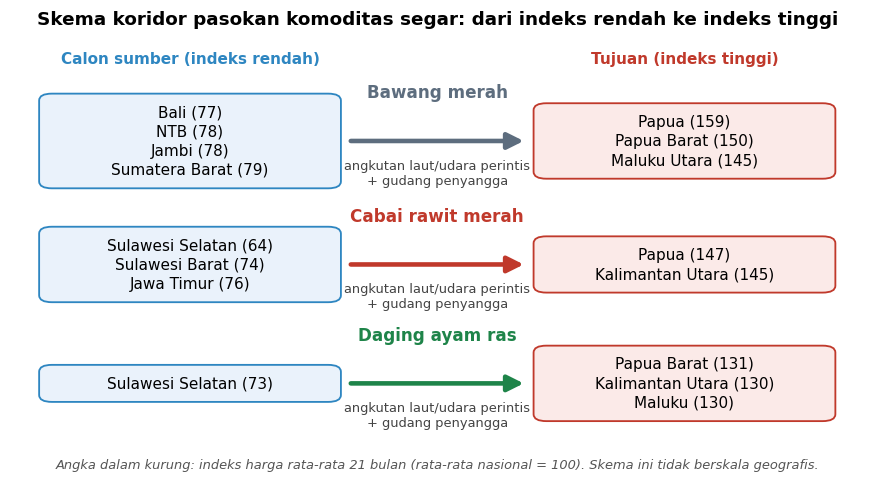

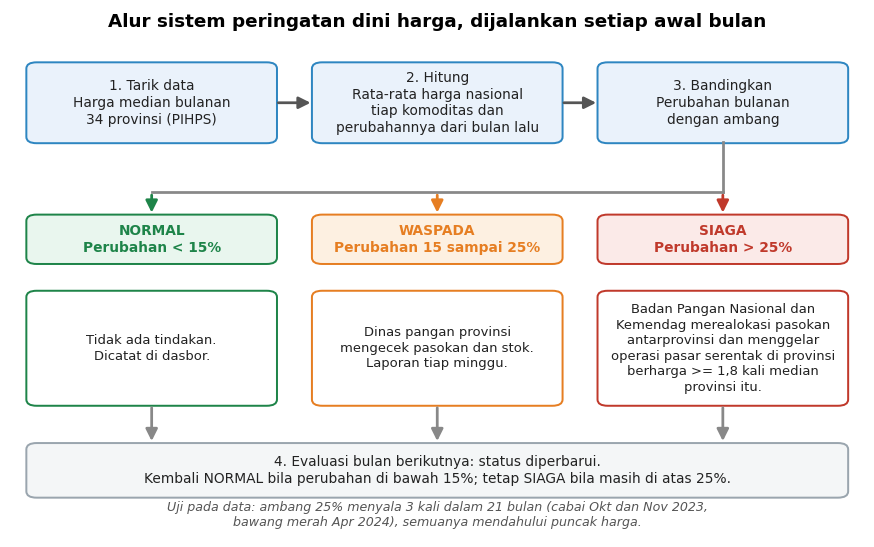

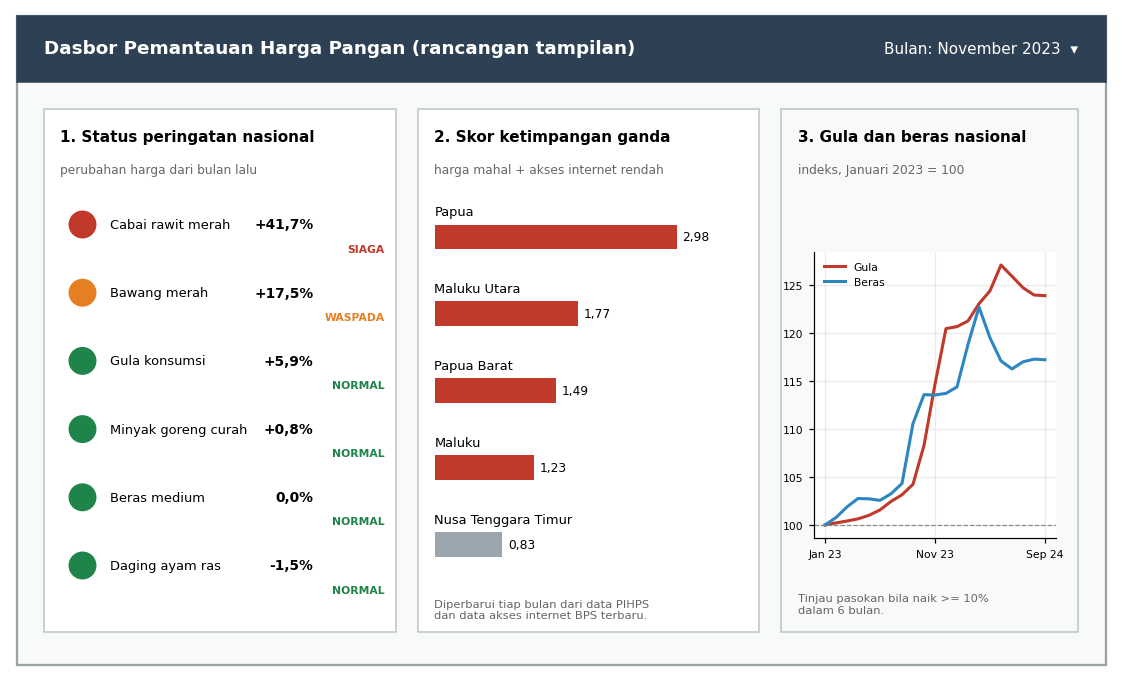

In [88]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle
HIJAU = "#1E8449"

# ---------- Gambar 4.1: skema koridor ----------
WK = {"Bawang merah": "#5D6D7E", "Cabai rawit merah": "#C0392B", "Daging ayam ras": "#1E8449"}
rows = [("Bawang merah", ["Bali (77)", "NTB (78)", "Jambi (78)", "Sumatera Barat (79)"], ["Papua (159)", "Papua Barat (150)", "Maluku Utara (145)"]),
        ("Cabai rawit merah", ["Sulawesi Selatan (64)", "Sulawesi Barat (74)", "Jawa Timur (76)"], ["Papua (147)", "Kalimantan Utara (145)"]),
        ("Daging ayam ras", ["Sulawesi Selatan (73)"], ["Papua Barat (131)", "Kalimantan Utara (130)", "Maluku (130)"])]
fig, ax = plt.subplots(figsize=(10, 5.4)); ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")
ax.text(5, 9.75, "Skema koridor pasokan komoditas segar: dari indeks rendah ke indeks tinggi", ha="center", fontsize=12, fontweight="bold")
ax.text(2.1, 8.9, "Calon sumber (indeks rendah)", ha="center", fontsize=10, color="#2E86C1", fontweight="bold")
ax.text(7.9, 8.9, "Tujuan (indeks tinggi)", ha="center", fontsize=10, color="#C0392B", fontweight="bold")
for (kom, src, dst), y in zip(rows, [7.0, 4.3, 1.7]):
    c = WK[kom]; ax.text(5, y + 1.15, kom, ha="center", fontsize=11, fontweight="bold", color=c)
    for x, items, fc, ec in [(2.1, src, "#EAF2FB", "#2E86C1"), (7.9, dst, "#FBEAE8", "#C0392B")]:
        h = 0.42 * len(items) + 0.35
        ax.add_patch(FancyBboxPatch((x - 1.75, y - h / 2 + 0.2), 3.5, h, boxstyle="round,pad=0.02,rounding_size=0.15", fc=fc, ec=ec, lw=1.2))
        for i, t in enumerate(items): ax.text(x, y + 0.2 + h / 2 - 0.38 - 0.42 * i, t, ha="center", va="center", fontsize=10)
    ax.add_patch(FancyArrowPatch((3.95, y + 0.2), (6.05, y + 0.2), arrowstyle="-|>", mutation_scale=22, lw=3, color=c))
    ax.text(5, y - 0.2, "angkutan laut/udara perintis\n+ gudang penyangga", ha="center", va="top", fontsize=8.5, color="#444")
ax.text(5, 0.05, "Angka dalam kurung: indeks harga rata-rata 21 bulan (rata-rata nasional = 100). Skema ini tidak berskala geografis.", ha="center", fontsize=8.5, color="#555", style="italic")
fig.savefig("grafik/11_skema_koridor.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- Gambar 4.2: alur peringatan dini ----------
def kotak(ax, x, y, w, h, txt, fc, ec, fs=9, bold=False, tc="#222"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fc, ec=ec, lw=1.3))
    ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal", color=tc, linespacing=1.25)
def panah(ax, p, q, c="#555"): ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=16, lw=1.8, color=c))
fig, ax = plt.subplots(figsize=(10, 6.2)); ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")
ax.text(5, 9.7, "Alur sistem peringatan dini harga, dijalankan setiap awal bulan", ha="center", fontsize=12, fontweight="bold")
kotak(ax, 0.2, 7.5, 2.9, 1.5, "1. Tarik data\nHarga median bulanan\n34 provinsi (PIHPS)", "#EAF2FB", BIRU)
kotak(ax, 3.55, 7.5, 2.9, 1.5, "2. Hitung\nRata-rata harga nasional\ntiap komoditas dan\nperubahannya dari bulan lalu", "#EAF2FB", BIRU)
kotak(ax, 6.9, 7.5, 2.9, 1.5, "3. Bandingkan\nPerubahan bulanan\ndengan ambang", "#EAF2FB", BIRU)
panah(ax, (3.1, 8.25), (3.55, 8.25)); panah(ax, (6.45, 8.25), (6.9, 8.25))
status = [("NORMAL", HIJAU, "#E9F6EE", "Perubahan < 15%", "Tidak ada tindakan.\nDicatat di dasbor."),
          ("WASPADA", ORANYE, "#FDF0E1", "Perubahan 15 sampai 25%", "Dinas pangan provinsi\nmengecek pasokan dan stok.\nLaporan tiap minggu."),
          ("SIAGA", MERAH, "#FBEAE8", "Perubahan > 25%", "Badan Pangan Nasional dan\nKemendag merealokasi pasokan\nantarprovinsi dan menggelar\noperasi pasar serentak di provinsi\nberharga >= 1,8 kali median\nprovinsi itu.")]
for i, (nm, ec, fc, cond, act) in enumerate(status):
    x = 0.2 + i * 3.35
    kotak(ax, x, 5.2, 2.9, 0.9, f"{nm}\n{cond}", fc, ec, 9, True, ec)
    kotak(ax, x, 2.5, 2.9, 2.15, act, "white", ec, 8.6)
    panah(ax, (x + 1.45, 6.55), (x + 1.45, 6.1), ec)
    panah(ax, (x + 1.45, 2.5), (x + 1.45, 1.75), "#888")
ax.plot([1.65, 8.35], [6.55, 6.55], color="#888", lw=1.8); ax.plot([8.35, 8.35], [7.5, 6.55], color="#888", lw=1.8)
kotak(ax, 0.2, 0.75, 9.6, 1.0, "4. Evaluasi bulan berikutnya: status diperbarui.\nKembali NORMAL bila perubahan di bawah 15%; tetap SIAGA bila masih di atas 25%.", "#F4F6F7", ABU)
ax.text(5, 0.2, "Uji pada data: ambang 25% menyala 3 kali dalam 21 bulan (cabai Okt dan Nov 2023,\nbawang merah Apr 2024), semuanya mendahului puncak harga.", ha="center", fontsize=8.3, color="#555", style="italic")
fig.savefig("grafik/12_alur_peringatan_dini.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- Gambar 4.3: rancangan tampilan dasbor (contoh November 2023) ----------
chg = (nas.pct_change() * 100).loc["2023-11"]
idx_nas = nas / nas.iloc[0] * 100
top5 = prov["skor"].sort_values(ascending=False).head(5)
NM = {"Cabai Rawit Merah": "Cabai rawit merah", "Bawang Merah": "Bawang merah", "Gula Konsumsi": "Gula konsumsi",
      "Beras Medium": "Beras medium", "Daging Ayam Ras": "Daging ayam ras", "Minyak Goreng Curah": "Minyak goreng curah"}
fig = plt.figure(figsize=(10, 6)); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off")
ax.add_patch(Rectangle((0.05, 0.05), 9.9, 5.9, fc="#F8F9F9", ec="#99A3A4", lw=1.5))
ax.add_patch(Rectangle((0.05, 5.35), 9.9, 0.6, fc="#2E4053", ec="#2E4053"))
ax.text(0.3, 5.65, "Dasbor Pemantauan Harga Pangan (rancangan tampilan)", color="white", fontsize=12, fontweight="bold", va="center")
ax.text(9.7, 5.65, "Bulan: November 2023  \u25be", color="white", fontsize=10, va="center", ha="right")
ax.add_patch(Rectangle((0.3, 0.35), 3.2, 4.75, fc="white", ec="#BDC3C7"))
ax.text(0.45, 4.85, "1. Status peringatan nasional", fontsize=10, fontweight="bold", va="center")
ax.text(0.45, 4.55, "perubahan harga dari bulan lalu", fontsize=8, color="#666", va="center")
for i, k in enumerate(chg.sort_values(ascending=False).index):
    c = chg[k]; col = MERAH if c > 25 else (ORANYE if c >= 15 else HIJAU); st = "SIAGA" if c > 25 else ("WASPADA" if c >= 15 else "NORMAL")
    y = 4.05 - i * 0.62
    ax.add_patch(plt.Circle((0.65, y), 0.12, color=col)); ax.text(0.9, y, NM[k], fontsize=8.5, va="center")
    ax.text(2.75, y, (f"{c:+.1f}%" if abs(c) >= 0.05 else "0,0%").replace(".", ","), fontsize=9, va="center", ha="right", fontweight="bold")
    ax.text(3.4, y - 0.22, st, fontsize=7, va="center", ha="right", color=col, fontweight="bold")
ax.add_patch(Rectangle((3.7, 0.35), 3.1, 4.75, fc="white", ec="#BDC3C7"))
ax.text(3.85, 4.85, "2. Skor ketimpangan ganda", fontsize=10, fontweight="bold", va="center")
ax.text(3.85, 4.55, "harga mahal + akses internet rendah", fontsize=8, color="#666", va="center")
for i, (p_, s_) in enumerate(top5.items()):
    y = 3.95 - i * 0.7
    ax.text(3.85, y + 0.22, p_, fontsize=8.5, va="center")
    ax.add_patch(Rectangle((3.85, y - 0.12), 2.2 * s_ / top5.max(), 0.22, fc=MERAH if i < 4 else ABU, ec="none"))
    ax.text(3.9 + 2.2 * s_ / top5.max(), y - 0.01, f"{s_:.2f}".replace(".", ","), fontsize=8, va="center")
ax.text(3.85, 0.55, "Diperbarui tiap bulan dari data PIHPS\ndan data akses internet BPS terbaru.", fontsize=7.5, color="#666", va="center")
ax.add_patch(Rectangle((7.0, 0.35), 2.7, 4.75, fc="none", ec="#BDC3C7"))
ax.text(7.15, 4.85, "3. Gula dan beras nasional", fontsize=10, fontweight="bold", va="center")
ax.text(7.15, 4.55, "indeks, Januari 2023 = 100", fontsize=8, color="#666", va="center")
ax3 = fig.add_axes([7.3 / 10, 1.2 / 6, 2.2 / 10, 2.6 / 6])
for k, c_, l_ in [("Gula Konsumsi", MERAH, "Gula"), ("Beras Medium", BIRU, "Beras")]:
    ax3.plot(range(len(idx_nas)), idx_nas[k].values, color=c_, lw=2, label=l_)
ax3.axhline(100, color="#888", lw=0.8, ls="--"); ax3.set_xticks([0, 10, 20]); ax3.set_xticklabels(["Jan 23", "Nov 23", "Sep 24"], fontsize=7)
ax3.tick_params(axis="y", labelsize=7); ax3.legend(fontsize=7, frameon=False, loc="upper left")
for s_ in ("top", "right"): ax3.spines[s_].set_visible(False)
ax.text(7.15, 0.6, "Tinjau pasokan bila naik >= 10%\ndalam 6 bulan.", fontsize=7.5, color="#666", va="center")
fig.savefig("grafik/13_rancangan_dasbor.png", dpi=200, bbox_inches="tight"); plt.show()

**Hasil dan implikasi.** Ketiga gambar ini menerjemahkan temuan menjadi tindakan: siapa mengirim ke mana (Solusi 1), kapan dan oleh siapa respons dijalankan (Solusi 2), dan apa yang dipantau pembuat kebijakan tiap bulan (Solusi 3). Dasbor pada Gambar 4.3 adalah rancangan tampilan, belum aplikasi yang dibangun.

### 3.14 Angka pendukung narasi (Bab III dan IV)
Sel ini menghitung angka-angka yang dikutip di proposal tetapi belum tercetak di sel sebelumnya: Tabel 3.3, rasio harga termahal terhadap termurah, selisih timur per bulan, kurs dan gula, lonjakan cabai, uji ambang 20 sampai 30%, indeks provinsi sasaran Solusi 1, dan peringkat pada bobot harga 70%. Semuanya dihitung dari data bersih, bukan diketik manual.

In [89]:
# Angka pendukung narasi Bab III dan IV (semua dihitung dari data bersih, tidak diketik manual)
TIMUR = ["Papua", "Papua Barat", "Maluku", "Maluku Utara"]

print("=== Tabel 3.3: rata-rata indeks harga empat provinsi timur dan provinsi lain ===")
t = pd.DataFrame({"4 provinsi timur": indeks_pk.loc[TIMUR].mean(), "Provinsi lain": indeks_pk.drop(TIMUR).mean()})
t["Selisih"] = t["4 provinsi timur"] - t["Provinsi lain"]
print(t.sort_values("Selisih", ascending=False).round(0).astype(int).to_string())

print("\n=== Rasio harga rata-rata provinsi termahal terhadap termurah ===")
pm = v12.groupby(["komoditas", "provinsi"])["harga_median"].mean().unstack(0)
for k in pm.columns:
    s = pm[k].dropna()
    print(f"{k}: {s.max() / s.min():.2f} kali (termahal {s.idxmax()}, termurah {s.idxmin()})")

print("\n=== Premium timur menurut waktu ===")
rel = valid.groupby(["provinsi", "periode"])["indeks_rel"].mean().unstack(0)
sel = rel[TIMUR].mean(axis=1) - rel.drop(columns=TIMUR).mean(axis=1)
print(f"Selisih indeks timur dan provinsi lain per bulan: {sel.min():.1f} ({sel.idxmin()}) sampai {sel.max():.1f} ({sel.idxmax()})")
for p in ["Papua", "Papua Barat", "Maluku Utara"]:
    print(f"{p}: indeks 3 bulan awal {rel[p].iloc[:3].mean():.1f} -> 3 bulan akhir {rel[p].iloc[-3:].mean():.1f}")

print("\n=== Kurs dan gula ===")
kurs = df.groupby("periode")["usd_idr_median"].first()
print(f"Kurs {kurs.index[0]}: {kurs.iloc[0]:,.0f} -> {kurs.index[-1]}: {kurs.iloc[-1]:,.0f} ({(kurs.iloc[-1] / kurs.iloc[0] - 1) * 100:.1f}%)")
g = valid[valid.komoditas == "Gula Konsumsi"].pivot_table(index="provinsi", columns="periode", values="harga_median")
m24 = [m for m in g.columns if m.startswith("2024")]
m23 = [m for m in g.columns if m.startswith("2023") and int(m[5:]) <= 9]
yoy = (g[m24].mean(axis=1) / g[m23].mean(axis=1) - 1) * 100
print(f"Gula, rata-rata Jan-Sep 2024 dibanding Jan-Sep 2023: rata-rata {yoy.mean():.1f}%, rentang {yoy.min():.1f}% sampai {yoy.max():.1f}%")

print("\n=== Lonjakan cabai dan uji ambang peringatan dini ===")
ch = nas.pct_change() * 100
idx = nas / nas.iloc[0] * 100
print("Cabai, perubahan bulanan:", ", ".join(f"{p} {ch.loc[p, 'Cabai Rawit Merah']:+.1f}%" for p in ["2023-10", "2023-11", "2023-12", "2024-01"]))
naik = ch.stack()
naik = naik[naik > 0]
bawah, atas = naik[naik < 25].max(), naik[naik >= 25].min()
print(f"Kenaikan bulanan terbesar di bawah 25%: {bawah:.1f}% | terkecil di atas 25%: {atas:.1f}% | titik tengah {(bawah + atas) / 2:.1f}%")
for a in (20, 22.5, 25, 27.5, 30):
    print(f"  ambang {a}%: menyala {(naik > a).sum()} kali")
print(f"Cabai: indeks {idx.loc['2023-10', 'Cabai Rawit Merah']:.0f} saat alarm Oktober 2023, puncak {idx['Cabai Rawit Merah'].max():.0f} ({idx['Cabai Rawit Merah'].idxmax()})")
print(f"Bawang merah: indeks {idx.loc['2024-04', 'Bawang Merah']:.0f} saat alarm April 2024, puncak {idx['Bawang Merah'].max():.0f} ({idx['Bawang Merah'].idxmax()})")

print("\n=== Provinsi berindeks harga > 100 dan akses internetnya ===")
print(prov[prov.indeks_harga > 100].sort_values("indeks_harga", ascending=False)[["indeks_harga", "internet", "kuadran"]].round(1).to_string())
print("\nIndeks Kalimantan Utara pada komoditas sasaran Solusi 1:")
print(indeks_pk.loc[["Kalimantan Utara"], ["Bawang Merah", "Cabai Rawit Merah", "Daging Ayam Ras"]].round(0).to_string())

print("\n=== Peringkat skor dengan bobot harga 70% (variasi E) ===")
zs = lambda s: (s - s.mean()) / s.std()
e = (0.7 * zs(prov.indeks_harga) + 0.3 * zs(-prov.internet)).sort_values(ascending=False)
print(e.head(8).round(3).to_string())
print("Peringkat Nusa Tenggara Timur:", list(e.index).index("Nusa Tenggara Timur") + 1)


=== Tabel 3.3: rata-rata indeks harga empat provinsi timur dan provinsi lain ===
                     4 provinsi timur  Provinsi lain  Selisih
komoditas                                                    
Bawang Merah                      144             94       50
Cabai Rawit Merah                 133             95       38
Daging Ayam Ras                   125             97       28
Minyak Goreng Curah               117             98       19
Beras Medium                      111             98       13
Gula Konsumsi                     110             99       11

=== Rasio harga rata-rata provinsi termahal terhadap termurah ===
Bawang Merah: 1.99 kali (termahal Papua, termurah Bali)
Beras Medium: 1.24 kali (termahal Papua Barat, termurah Jawa Timur)
Cabai Rawit Merah: 2.19 kali (termahal Kalimantan Utara, termurah Sulawesi Selatan)
Daging Ayam Ras: 1.78 kali (termahal Papua Barat, termurah Sulawesi Selatan)
Gula Konsumsi: 1.22 kali (termahal Papua, termurah Jawa Timur)
Minyak G

## 4. Ringkasan Angka Temuan

Sel ini mencetak angka-angka kunci hasil analisis di atas, supaya bisa dikutip langsung di Bab III dan IV proposal. Interpretasi dan rekomendasi solusi disusun di proposal.

In [90]:
print("=== DATA ===")
print(f"Baris mentah {len(raw):,} -> bersih {len(df):,} ({len(df)-len(valid)} baris ditandai parsial, analisis utama {len(valid):,} baris)")
print(f"Duplikat dibuang: {n_dup} | Harga kosong tak terpulihkan: {int(df['harga_median'].isna().sum())}")
print()
print("=== HARGA ===")
print("Indeks Sep 2024 (Jan 2023 = 100):", ", ".join(f"{k} {v:.0f}" for k, v in akhir.items()))
print("CV rata-rata:", ", ".join(f"{k} {v:.1f}%" for k, v in cv_kom.sort_values(ascending=False).items()))
print(f"Cabai Des 2023: {int((rasio >= 1.8).sum())} provinsi >= 1,8x median provinsi ({', '.join(rasio[rasio >= 1.8].index)})")
print()
print("=== KETIMPANGAN ===")
top5_harga = indeks_prov.sort_values(ascending=False).head(5)
print("5 indeks harga tertinggi:", ", ".join(f"{k} {v:.1f}" for k, v in top5_harga.items()))
print("5 akses internet terendah:", ", ".join(f"{k} {v:.1f}%" for k, v in prov['internet'].sort_values().head(5).items()))
print(f"Spearman internet vs indeks harga: rho = {rho:.2f}, p = {p_rho:.2f} (n = 34)")
print("Kuadran:", prov['kuadran'].value_counts().to_dict())
print("Provinsi prioritas (skor ganda):", ", ".join(prioritas))
print(f"Rata-rata gap gender 34 provinsi: {prov['gap_gender'].mean():.1f} poin; prioritas: {prov.loc[prioritas, 'gap_gender'].mean():.1f} poin")
print(f"Provinsi dengan akses laki-laki > perempuan: {n_lk} dari 34")

=== DATA ===
Baris mentah 4,334 -> bersih 4,284 (23 baris ditandai parsial, analisis utama 4,261 baris)
Duplikat dibuang: 50 | Harga kosong tak terpulihkan: 5

=== HARGA ===
Indeks Sep 2024 (Jan 2023 = 100): Gula Konsumsi 124, Beras Medium 117, Minyak Goreng Curah 110, Daging Ayam Ras 99, Cabai Rawit Merah 88, Bawang Merah 73
CV rata-rata: Cabai Rawit Merah 27.1%, Bawang Merah 20.2%, Gula Konsumsi 9.8%, Beras Medium 7.3%, Daging Ayam Ras 5.3%, Minyak Goreng Curah 4.5%
Cabai Des 2023: 15 provinsi >= 1,8x median provinsi (Sulawesi Utara, Gorontalo, Sulawesi Tengah, Sulawesi Selatan, Sulawesi Tenggara, Sulawesi Barat, Jawa Tengah, Jawa Timur, DI Yogyakarta, Bali, Maluku Utara, DKI Jakarta, Jawa Barat, Banten, Kalimantan Utara)

=== KETIMPANGAN ===
5 indeks harga tertinggi: Papua 126.0, Papua Barat 125.2, Maluku Utara 124.4, Kalimantan Utara 118.2, Maluku 117.9
5 akses internet terendah: Papua 29.8%, Nusa Tenggara Timur 51.1%, Maluku Utara 53.5%, Sulawesi Tengah 58.2%, Maluku 58.5%
Spearma

## 5. Lampiran: daftar berkas keluaran
- `print_2026_ekonomi_clean.csv`: data bersih lengkap dengan kolom penanda (`flag_data_parsial`, `flag_outlier_iqr`, `penilaian_outlier`)
- `log_cleaning.csv`: catatan perubahan tiap langkah
- folder `grafik/`: seluruh grafik (PNG) yang dipakai di laporan